In [1]:
!pip install afinn
!pip install nltk

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import re
import nltk
from afinn import Afinn
from sklearn.preprocessing import StandardScaler
from mpl_toolkits.mplot3d import Axes3D
from nltk.tokenize import word_tokenize

In [ ]:
#COLAB
from google.colab import drive
drive.mount('/content/drive')
df_tweet = pd.read_csv('/content/drive/MyDrive/PROGETTO_DATA/datasets/mvsc_tweet.csv') #modifica
emoji = pd.read_csv('/content/drive/MyDrive/PROGETTO_DATA/datasets/mvsc_emoji.csv') #modifica

In [4]:
# Distribution graphs (histogram/bar graph) of column data
def plotPerColumnDistribution(df, nGraphShown, nGraphPerRow):
    nunique = df.nunique()
    df = df[[col for col in df if nunique[col] > 1 and nunique[col] < 50]] # For displaying purposes, pick columns that have between 1 and 50 unique values
    nRow, nCol = df.shape
    columnNames = list(df)
    nGraphRow = (nCol + nGraphPerRow - 1) / nGraphPerRow
    plt.figure(num = None, figsize = (6 * nGraphPerRow, 8 * nGraphRow), dpi = 80, facecolor = 'w', edgecolor = 'k')
    for i in range(min(nCol, nGraphShown)):
        plt.subplot(nGraphRow, nGraphPerRow, i + 1)
        columnDf = df.iloc[:, i]
        if (not np.issubdtype(type(columnDf.iloc[0]), np.number)):
            valueCounts = columnDf.value_counts()
            valueCounts.plot.bar()
        else:
            columnDf.hist()
        plt.ylabel('Number of sentences')
        plt.xticks(rotation = 90)
        plt.title(f'{columnNames[i]} (column {i})')
    plt.tight_layout(pad = 1.0, w_pad = 1.0, h_pad = 1.0)
    plt.show()

In [ ]:
#df_tweet = pd.read_csv("datasets/mvsc_tweet.csv", sep="\t", encoding="latin1")
df_tweet.to_csv('tweet_originali.csv', index=False)

#df_emoji = pd.read_csv("datasets/mvsc_emoji.csv", sep="\t", encoding="latin1")
df_tweet.head()


,tweet_id,tweet_text,user_id,keyword,emotion_A1,Irony_A1,Implicit-Explicit_A1,Subjectivity_A1,Tweet Sentiment_A1,emotion_A2,Irony_A2,Implicit-Explicit_A2,Subjectivity_A2,Tweet Sentiment_A2,emotion_A3,Irony_A3,Implicit-Explicit_A3,Subjectivity_A3,Tweet Sentiment_A3
0,697021002379890689,#MARVEL #COMICS Deadpool & the Mercs for Money...,2873144464,deadpool,NaN,Not Ironic,NaN,Objective,NaN,NaN,Not Ironic,NaN,Objective,NaN,NaN,Not Ironic,NaN,Objective,NaN
1,697026986795872256,#HughJackman Plays Coy on Possible Wolverine C...,2603224578,deadpool,NaN,Not Ironic,NaN,Objective,NaN,NaN,Not Ironic,NaN,Objective,NaN,NaN,Not Ironic,NaN,Objective,NaN
2,697027997824638976,Blake Lively and Ryan Reynolds attend the 'Dea...,17637890,deadpool,NaN,Not Ironic,NaN,Objective,NaN,NaN,Not Ironic,NaN,Objective,NaN,NaN,Not Ironic,NaN,Objective,NaN
3,697035441153953792,Really hope Deadpool is still showing when I g...,196255919,deadpool,anticipation,Not Ironic,Implicit,Subjective,Positive,fear,Not Ironic,NaN,Objective,NaN,anticipation,Not Ironic,Implicit,Subjective,Positive
4,697038361857396736,"deadpool here, deadpool there. okay.",271503690,deadpool,NaN,Not Ironic,NaN,Objective,NaN,surprise,Not Ironic,Implicit,Subjective,Neutral,disgust,Not Ironic,Implicit,Subjective,Negative


In [6]:
df_emoji.head()

,tweet_id,emoji_position,Tweet Sent Emoji_A1,Tweet Sent Emoji_A2,Tweet Sent Emoji_A3
0,697061232810008576,1,Positive,Positive,Positive
1,697147578631221249,1,Positive,Positive,Positive
2,697156694799970304,1,Neutral,Negative,Negative
3,697166947587330048,1,Positive,Negative,Negative
4,697181575344230402,1,Positive,Positive,Positive


In [7]:
print(df_tweet.shape)
print(df_emoji.shape)
print("Columns:", df_tweet.columns)
print("Data types:\n", df_tweet.dtypes)

(3000, 19)
(589, 5)
Columns: Index(['tweet_id', 'tweet_text', 'user_id', 'keyword', 'emotion_A1',
       'Irony_A1', 'Implicit-Explicit_A1', 'Subjectivity_A1',
       'Tweet Sentiment_A1', 'emotion_A2', 'Irony_A2', 'Implicit-Explicit_A2',
       'Subjectivity_A2', 'Tweet Sentiment_A2', 'emotion_A3', 'Irony_A3',
       'Implicit-Explicit_A3', 'Subjectivity_A3', 'Tweet Sentiment_A3'],
      dtype='object')
Data types:
 tweet_id                 int64
tweet_text              object
user_id                  int64
keyword                 object
emotion_A1              object
Irony_A1                object
Implicit-Explicit_A1    object
Subjectivity_A1         object
Tweet Sentiment_A1      object
emotion_A2              object
Irony_A2                object
Implicit-Explicit_A2    object
Subjectivity_A2         object
Tweet Sentiment_A2      object
emotion_A3              object
Irony_A3                object
Implicit-Explicit_A3    object
Subjectivity_A3         object
Tweet Sentiment_A3   

In [8]:
tweet = df_tweet[['tweet_id','tweet_text', 'user_id', 'keyword' , 'Tweet Sentiment_A1','Tweet Sentiment_A2', 'Tweet Sentiment_A3']]
emoji = df_emoji.copy()
tweet

,tweet_id,tweet_text,user_id,keyword,Tweet Sentiment_A1,Tweet Sentiment_A2,Tweet Sentiment_A3
0,697021002379890689,#MARVEL #COMICS Deadpool & the Mercs for Money...,2873144464,deadpool,NaN,NaN,NaN
1,697026986795872256,#HughJackman Plays Coy on Possible Wolverine C...,2603224578,deadpool,NaN,NaN,NaN
2,697027997824638976,Blake Lively and Ryan Reynolds attend the 'Dea...,17637890,deadpool,NaN,NaN,NaN
3,697035441153953792,Really hope Deadpool is still showing when I g...,196255919,deadpool,Positive,NaN,Positive
4,697038361857396736,"deadpool here, deadpool there. okay.",271503690,deadpool,NaN,Neutral,Negative
...,...,...,...,...,...,...,...
2995,764509349674749954,RT @TVMcGee: Well that was horrifically bad. I...,84974931,suicidesquad,Negative,Negative,Positive
2996,764514512762535936,RT @ahmadkhojaa: I need to watch #SuicideSquad...,370332569,suicidesquad,Positive,Positive,Positive
2997,764522830641758208,RT @FizzVsTheWorld: And that was #SuicideSquad...,176219580,suicidesquad,Negative,Neutral,Neutral
2998,764522845779001346,RT @SiamCarDeal: WHAT that beast call the VAYD...,128794394,suicidesquad,NaN,NaN,NaN


In [9]:
emoji

,tweet_id,emoji_position,Tweet Sent Emoji_A1,Tweet Sent Emoji_A2,Tweet Sent Emoji_A3
0,697061232810008576,1,Positive,Positive,Positive
1,697147578631221249,1,Positive,Positive,Positive
2,697156694799970304,1,Neutral,Negative,Negative
3,697166947587330048,1,Positive,Negative,Negative
4,697181575344230402,1,Positive,Positive,Positive
...,...,...,...,...,...
584,764297220753469440,1,Negative,Positive,Negative
585,764385105653538816,1,Neutral,Negative,Negative
586,764466249053179904,1,Positive,Positive,Positive
587,764475999656435712,1,Positive,Positive,Negative


In [10]:
tweet_deadpool= tweet[tweet['keyword']== 'deadpool'].copy()
tweet_suicide= tweet[tweet['keyword']== 'suicidesquad'].copy()
tweet_deadpool.nunique()


tweet_id              1500
tweet_text            1497
user_id               1489
keyword                  1
Tweet Sentiment_A1       3
Tweet Sentiment_A2       3
Tweet Sentiment_A3       3
dtype: int64

In [11]:
print(tweet_deadpool['Tweet Sentiment_A1'].isna().sum())
print(tweet_deadpool['Tweet Sentiment_A2'].isna().sum())
print(tweet_deadpool['Tweet Sentiment_A3'].isna().sum())


395
517
520


In [12]:
print(tweet_suicide['Tweet Sentiment_A1'].isna().sum())
print(tweet_suicide['Tweet Sentiment_A2'].isna().sum())
print(tweet_suicide['Tweet Sentiment_A3'].isna().sum())

361
511
468


In [13]:
tweet_deadpool.drop(columns=['user_id', 'keyword'], inplace=True)
tweet_suicide.drop(columns=['user_id', 'keyword'], inplace=True)


In [14]:
tweets_dp = tweet_deadpool['tweet_text'] 
tweets_suicide=tweet_suicide['tweet_text']
tweets_dp.head()

0    #MARVEL #COMICS Deadpool & the Mercs for Money...
1    #HughJackman Plays Coy on Possible Wolverine C...
2    Blake Lively and Ryan Reynolds attend the 'Dea...
3    Really hope Deadpool is still showing when I g...
4                 deadpool here, deadpool there. okay.
Name: tweet_text, dtype: object

In [15]:
from afinn import Afinn
afinn = Afinn(emoticons=True)

In [16]:
tweet_suicide['afinn'] = tweet_suicide["tweet_text"].apply(afinn.score) 
tweet_suicide[['Tweet Sentiment_A1','Tweet Sentiment_A2', 'Tweet Sentiment_A3', 'afinn', 'tweet_text']].head(10)


,Tweet Sentiment_A1,Tweet Sentiment_A2,Tweet Sentiment_A3,afinn,tweet_text
1500,Negative,Negative,Negative,2.0,RT @GoMoggle: It was interesting looking for a...
1501,NaN,NaN,Positive,0.0,RT @MargotRobbie: We're going on a field trip!...
1502,Positive,Positive,Positive,-1.0,RT @SergioEES: I need those cut scenes of the ...
1503,NaN,NaN,Positive,-3.0,RT @TheWrap: #SuicideSquad Destroys August Rec...
1504,Negative,Neutral,Negative,0.0,RT @ZoomEarth_2: #SuicideSquad continued the t...
1505,Positive,Positive,Positive,-2.0,RT @SuicideSquadUK: Time to get a little bit c...
1506,Neutral,NaN,Negative,0.0,RT @jay_hernandez: Trying real hard to be cool...
1507,Positive,Positive,Positive,0.0,RT @RebeccaMuir_: I don't understand why #Suic...
1508,Negative,Negative,Positive,2.0,RT @MatthewACherry: I can't help but think tha...
1509,Negative,NaN,Negative,-2.0,RT @MetroUK: Jared Letos Joker stars in Suici...


In [17]:
tweet_deadpool['afinn'] = tweet_deadpool["tweet_text"].apply(afinn.score) 
tweet_deadpool[['Tweet Sentiment_A1','Tweet Sentiment_A2', 'Tweet Sentiment_A3', 'afinn', 'tweet_text']].head(10)

,Tweet Sentiment_A1,Tweet Sentiment_A2,Tweet Sentiment_A3,afinn,tweet_text
0,NaN,NaN,NaN,3.0,#MARVEL #COMICS Deadpool & the Mercs for Money...
1,NaN,NaN,NaN,0.0,#HughJackman Plays Coy on Possible Wolverine C...
2,NaN,NaN,NaN,5.0,Blake Lively and Ryan Reynolds attend the 'Dea...
3,Positive,NaN,Positive,2.0,Really hope Deadpool is still showing when I g...
4,NaN,Neutral,Negative,0.0,"deadpool here, deadpool there. okay."
5,NaN,Positive,NaN,8.0,RT @TinaTurnbowMUP: Last night at the #deadpoo...
6,Neutral,NaN,NaN,2.0,Am I trippin or does it look like Red skull in...
7,Positive,Positive,Positive,0.0,DEADPOOL tomorrow
8,Positive,Positive,Positive,0.0,RT @AntCao_: Deadpool is a must on Friday
9,NaN,NaN,NaN,0.0,"Everything You Need to Know About Deadpool, Ry..."


In [18]:
from collections import Counter
import numpy as np

def maggioranza_flessibile(row):
    voti = [v for v in [row['Tweet Sentiment_A1'], row['Tweet Sentiment_A2'], row['Tweet Sentiment_A3']] if pd.notna(v)]
    
    if not voti:
        return np.nan  # Nessun voto disponibile
    conta = Counter(voti)
    if conta.most_common(1)[0][1] >= 2:
        return conta.most_common(1)[0][0]  # Maggioranza chiara
    elif len(conta) == 1:
        return voti[0]  # Tutti uguali
    else:
        return "Neutral"  # Disaccordo totale con voti diversi

tweet_deadpool['sentiment_gold'] = tweet_deadpool.apply(maggioranza_flessibile, axis=1)
tweet_suicide['sentiment_gold']= tweet_suicide.apply(maggioranza_flessibile, axis=1)



In [19]:
from collections import Counter

def maggioranza_flessibile(row):
    voti = [v for v in [row['Tweet Sent Emoji_A1'], row['Tweet Sent Emoji_A2'], row['Tweet Sent Emoji_A3']] if pd.notna(v)]
    
    if not voti:
        return np.nan  # Nessun voto disponibile
    conta = Counter(voti)
    if conta.most_common(1)[0][1] >= 2:
        return conta.most_common(1)[0][0]  # Maggioranza chiara
    elif len(conta) == 1:
        return voti[0]  # Tutti uguali
    else:
        return "Neutral"  # Disaccordo totale con voti diversi

emoji['sentiment_gold'] = emoji.apply(maggioranza_flessibile, axis=1)

In [20]:
emoji

,tweet_id,emoji_position,Tweet Sent Emoji_A1,Tweet Sent Emoji_A2,Tweet Sent Emoji_A3,sentiment_gold
0,697061232810008576,1,Positive,Positive,Positive,Positive
1,697147578631221249,1,Positive,Positive,Positive,Positive
2,697156694799970304,1,Neutral,Negative,Negative,Negative
3,697166947587330048,1,Positive,Negative,Negative,Negative
4,697181575344230402,1,Positive,Positive,Positive,Positive
...,...,...,...,...,...,...
584,764297220753469440,1,Negative,Positive,Negative,Negative
585,764385105653538816,1,Neutral,Negative,Negative,Negative
586,764466249053179904,1,Positive,Positive,Positive,Positive
587,764475999656435712,1,Positive,Positive,Negative,Positive


In [21]:
emoji.drop(columns=['Tweet Sent Emoji_A1', 'Tweet Sent Emoji_A2', 'Tweet Sent Emoji_A3'], inplace=True)
emoji

,tweet_id,emoji_position,sentiment_gold
0,697061232810008576,1,Positive
1,697147578631221249,1,Positive
2,697156694799970304,1,Negative
3,697166947587330048,1,Negative
4,697181575344230402,1,Positive
...,...,...,...
584,764297220753469440,1,Negative
585,764385105653538816,1,Negative
586,764466249053179904,1,Positive
587,764475999656435712,1,Positive


In [22]:
print(emoji['sentiment_gold'].isna().sum())

0


In [23]:
print(tweet_deadpool['sentiment_gold'].isna().sum())
print(tweet_suicide['sentiment_gold'].isna().sum())

260
245


In [24]:
def afinn_class(score):
    if score > 0:
        return 'Positive'
    elif score < 0:
        return 'Negative'
    else:
        return 'Neutral'

tweet_deadpool['afinn_class'] = tweet_deadpool['afinn'].apply(afinn_class)

tweet_suicide['afinn_class'] = tweet_suicide['afinn'].apply(afinn_class)

In [25]:
# Calcola accuratezza
accuracy_dp = (tweet_deadpool['afinn_class'] == tweet_deadpool['sentiment_gold']).mean()
print(f"Accuratezza Afinn rispetto agli annotatori: {accuracy_dp:.2f}")
accuracy_ss = (tweet_suicide['afinn_class'] == tweet_suicide['sentiment_gold']).mean()
print(f"Accuratezza Afinn rispetto agli annotatori: {accuracy_ss:.2f}")


Accuratezza Afinn rispetto agli annotatori: 0.41
Accuratezza Afinn rispetto agli annotatori: 0.39


In [26]:
disaccordi = tweet_deadpool[tweet_deadpool['afinn_class'] != tweet_deadpool['sentiment_gold']]
print(disaccordi[['tweet_text', 'sentiment_gold', 'afinn_class', 'afinn']].head())
disaccordi.shape


                                          tweet_text sentiment_gold  \
0  #MARVEL #COMICS Deadpool & the Mercs for Money...            NaN   
1  #HughJackman Plays Coy on Possible Wolverine C...            NaN   
2  Blake Lively and Ryan Reynolds attend the 'Dea...            NaN   
6  Am I trippin or does it look like Red skull in...        Neutral   
7                                  DEADPOOL tomorrow       Positive   

  afinn_class  afinn  
0    Positive    3.0  
1     Neutral    0.0  
2    Positive    5.0  
6    Positive    2.0  
7     Neutral    0.0  


(884, 8)

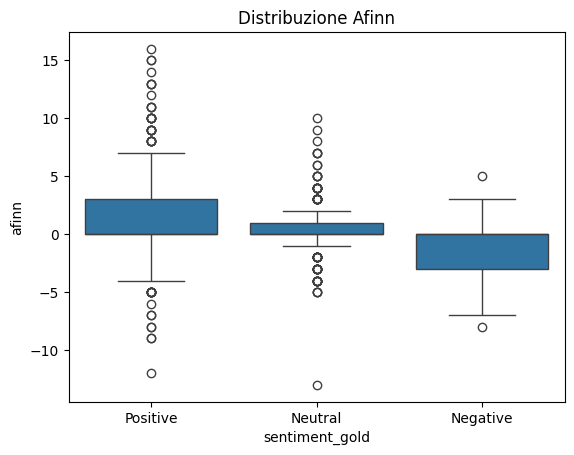

In [27]:
sns.boxplot(x='sentiment_gold', y='afinn', data=tweet_deadpool)
plt.title('Distribuzione Afinn')
plt.show()


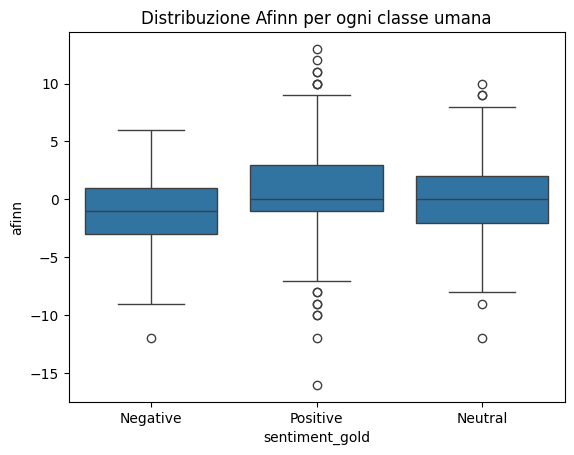

In [28]:
sns.boxplot(x='sentiment_gold', y='afinn', data=tweet_suicide)
plt.title('Distribuzione Afinn per ogni classe umana')
plt.show()

In [29]:
tweet_deadpool.afinn.value_counts()

afinn
 0.0     672
 3.0     150
 2.0     120
 1.0     113
 4.0      96
-1.0      56
-2.0      50
 6.0      44
-3.0      38
-4.0      37
 5.0      37
 7.0      25
-5.0      13
 8.0      10
 9.0       9
 10.0      7
-7.0       4
 13.0      3
-8.0       3
 11.0      3
 15.0      2
-9.0       2
 16.0      1
-6.0       1
-12.0      1
 14.0      1
-13.0      1
 12.0      1
Name: count, dtype: int64

Text(0, 0.5, 'Number of Sentences')

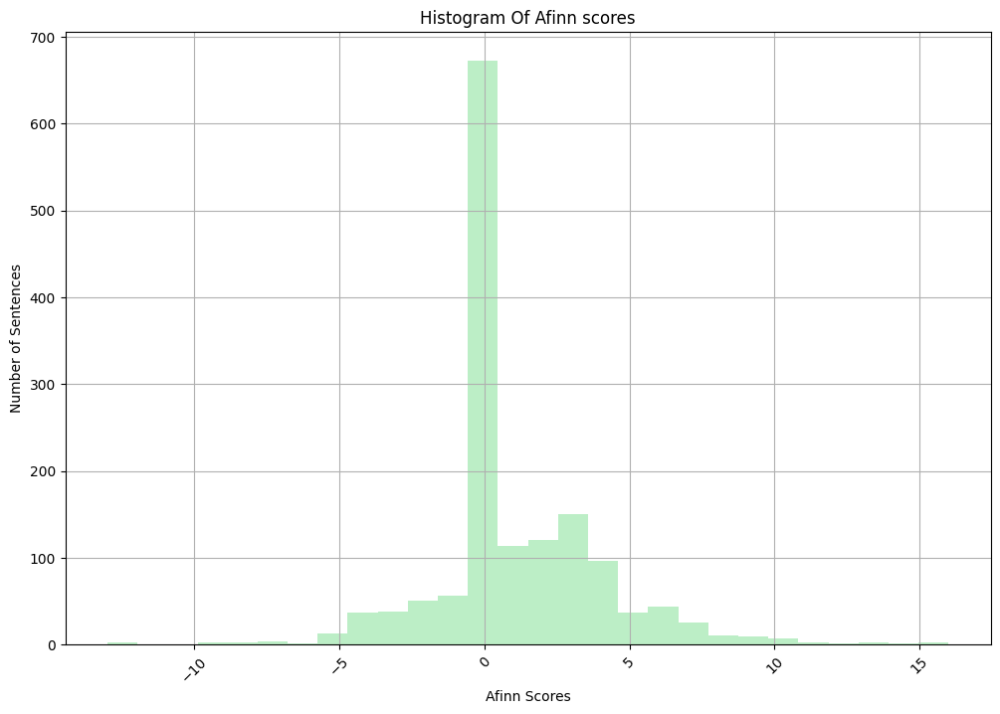

In [30]:
tweet_deadpool.afinn.plot(kind='hist', #takes the column name as input
        alpha=0.7,
        bins = abs(min(tweet_deadpool.afinn.value_counts().index.astype(int)) - max(tweet_deadpool.afinn.value_counts().index.astype(int)))-1,
        title='Histogram Of Afinn scores',
        rot=45,
        grid=True,
        figsize=(12,8),
        fontsize=10,
        color=['#A0E8AF'])
plt.xlabel('Afinn Scores')
plt.ylabel("Number of Sentences")

Text(0, 0.5, 'Number of Sentences')

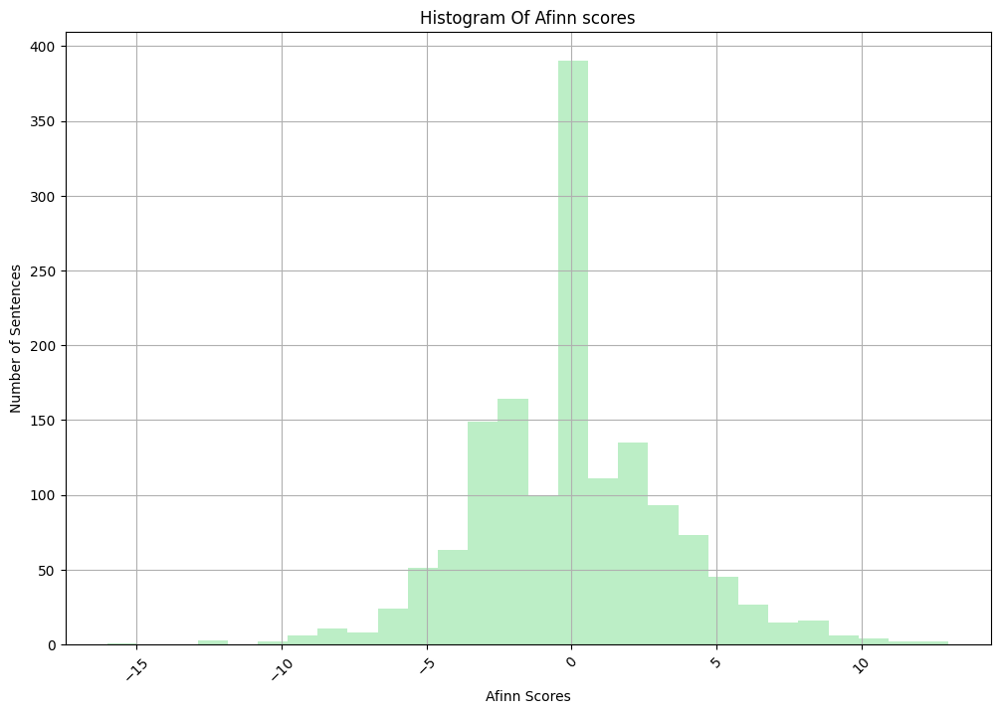

In [31]:
tweet_suicide.afinn.plot(kind='hist', #takes the column name as input
        alpha=0.7,
        bins = abs(min(tweet_suicide.afinn.value_counts().index.astype(int)) - max(tweet_suicide.afinn.value_counts().index.astype(int)))-1,
        title='Histogram Of Afinn scores',
        rot=45,
        grid=True,
        figsize=(12,8),
        fontsize=10,
        color=['#A0E8AF'])
plt.xlabel('Afinn Scores')
plt.ylabel("Number of Sentences")

In [32]:
tweet_deadpool.sentiment_gold.value_counts() #df. column_name .value_counts()

sentiment_gold
Positive    948
Neutral     238
Negative     54
Name: count, dtype: int64

In [33]:
tweet_suicide.sentiment_gold.value_counts() #df. column_name .value_counts()

sentiment_gold
Positive    636
Negative    324
Neutral     295
Name: count, dtype: int64

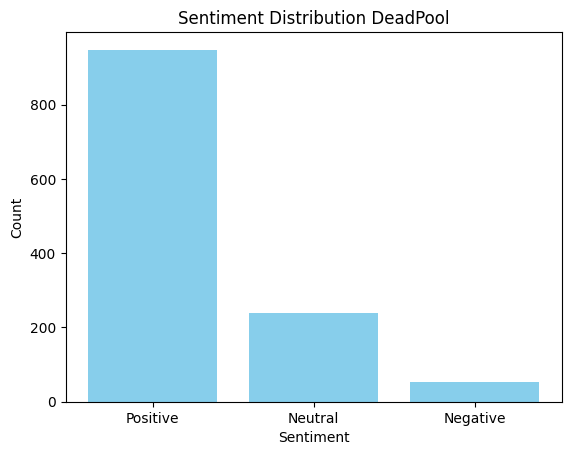

In [34]:
df_to_plot = {
    'sentiment': ["Positive", "Neutral", "Negative"],
    'count': [948, 238, 54]
    } 
plt.bar(df_to_plot['sentiment'], df_to_plot['count'], color='skyblue')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.title('Sentiment Distribution DeadPool')
plt.xticks(df_to_plot['sentiment'])
plt.show()

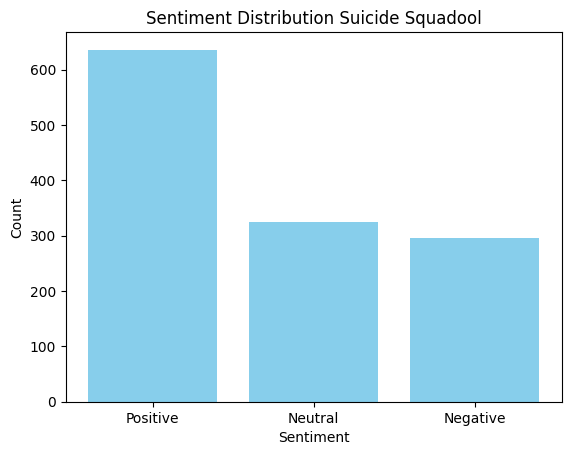

In [35]:
df_to_plot = {
    'sentiment': ["Positive", "Neutral", "Negative"],
    'count': [636, 324, 295]
    } 
plt.bar(df_to_plot['sentiment'], df_to_plot['count'], color='skyblue')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.title('Sentiment Distribution Suicide Squadool')
plt.xticks(df_to_plot['sentiment'])
plt.show()

In [36]:
tweet_deadpool

,tweet_id,tweet_text,Tweet Sentiment_A1,Tweet Sentiment_A2,Tweet Sentiment_A3,afinn,sentiment_gold,afinn_class
0,697021002379890689,#MARVEL #COMICS Deadpool & the Mercs for Money...,NaN,NaN,NaN,3.0,NaN,Positive
1,697026986795872256,#HughJackman Plays Coy on Possible Wolverine C...,NaN,NaN,NaN,0.0,NaN,Neutral
2,697027997824638976,Blake Lively and Ryan Reynolds attend the 'Dea...,NaN,NaN,NaN,5.0,NaN,Positive
3,697035441153953792,Really hope Deadpool is still showing when I g...,Positive,NaN,Positive,2.0,Positive,Positive
4,697038361857396736,"deadpool here, deadpool there. okay.",NaN,Neutral,Negative,0.0,Neutral,Neutral
...,...,...,...,...,...,...,...,...
1495,698938421763387392,Young Cancer Patient Was First To See Deadpool...,NaN,NaN,NaN,-1.0,NaN,Negative
1496,698938462624284672,@bedoya_8 dont go so we can get high and watch...,Neutral,Positive,Positive,0.0,Positive,Neutral
1497,698938628882493440,deadpool after i take the fam out to eat,Neutral,Neutral,NaN,0.0,Neutral,Neutral
1498,698938950350671873,Deadpool the perfect movie for Valentine's Day...,NaN,NaN,Positive,3.0,Positive,Positive


In [37]:
tweet_suicide

,tweet_id,tweet_text,Tweet Sentiment_A1,Tweet Sentiment_A2,Tweet Sentiment_A3,afinn,sentiment_gold,afinn_class
1500,762317617604558848,RT @GoMoggle: It was interesting looking for a...,Negative,Negative,Negative,2.0,Negative,Positive
1501,762317861536661505,RT @MargotRobbie: We're going on a field trip!...,NaN,NaN,Positive,0.0,Positive,Neutral
1502,762318029338255360,RT @SergioEES: I need those cut scenes of the ...,Positive,Positive,Positive,-1.0,Positive,Negative
1503,762318073613484032,RT @TheWrap: #SuicideSquad Destroys August Rec...,NaN,NaN,Positive,-3.0,Positive,Negative
1504,762318444679274496,RT @ZoomEarth_2: #SuicideSquad continued the t...,Negative,Neutral,Negative,0.0,Negative,Neutral
...,...,...,...,...,...,...,...,...
2995,764509349674749954,RT @TVMcGee: Well that was horrifically bad. I...,Negative,Negative,Positive,0.0,Negative,Neutral
2996,764514512762535936,RT @ahmadkhojaa: I need to watch #SuicideSquad...,Positive,Positive,Positive,0.0,Positive,Neutral
2997,764522830641758208,RT @FizzVsTheWorld: And that was #SuicideSquad...,Negative,Neutral,Neutral,-5.0,Neutral,Negative
2998,764522845779001346,RT @SiamCarDeal: WHAT that beast call the VAYD...,NaN,NaN,NaN,0.0,NaN,Neutral


In [38]:
tweet_deadpool.drop(columns=['Tweet Sentiment_A1', 'Tweet Sentiment_A2', 'Tweet Sentiment_A3'], inplace=True)
tweet_suicide.drop(columns=['Tweet Sentiment_A1', 'Tweet Sentiment_A2', 'Tweet Sentiment_A3'],inplace=True)
tweet_deadpool


,tweet_id,tweet_text,afinn,sentiment_gold,afinn_class
0,697021002379890689,#MARVEL #COMICS Deadpool & the Mercs for Money...,3.0,NaN,Positive
1,697026986795872256,#HughJackman Plays Coy on Possible Wolverine C...,0.0,NaN,Neutral
2,697027997824638976,Blake Lively and Ryan Reynolds attend the 'Dea...,5.0,NaN,Positive
3,697035441153953792,Really hope Deadpool is still showing when I g...,2.0,Positive,Positive
4,697038361857396736,"deadpool here, deadpool there. okay.",0.0,Neutral,Neutral
...,...,...,...,...,...
1495,698938421763387392,Young Cancer Patient Was First To See Deadpool...,-1.0,NaN,Negative
1496,698938462624284672,@bedoya_8 dont go so we can get high and watch...,0.0,Positive,Neutral
1497,698938628882493440,deadpool after i take the fam out to eat,0.0,Neutral,Neutral
1498,698938950350671873,Deadpool the perfect movie for Valentine's Day...,3.0,Positive,Positive


In [39]:
emoji = emoji[emoji['sentiment_gold'] != 'Topic'].copy()


In [40]:
print(emoji['sentiment_gold'].value_counts(dropna=False))


sentiment_gold
Positive    353
Negative    101
Neutral      59
Name: count, dtype: int64


In [41]:
from scipy.stats import mode

# 1. Trova i tweet con sentiment_gold NaN in tweet_deadpool
mask_nan = tweet_deadpool['sentiment_gold'].isna()
tweet_nan = tweet_deadpool[mask_nan]
mask_nan_ss = tweet_suicide['sentiment_gold'].isna()
tweet_nan_ss = tweet_suicide[mask_nan_ss]

# 2. Filtra le righe di emoji con tweet_id presenti in tweet_nan
emoji_filtered = emoji[emoji['tweet_id'].isin(tweet_nan['tweet_id'])]

# Funzione per calcolare la moda con pandas e prendere il primo valore (in caso di più modi)
def pandas_mode(series):
    modes = series.mode()
    if len(modes) > 0:
        return modes.iloc[0]
    else:
        return np.nan

mode_sentiment = emoji_filtered.groupby('tweet_id')['sentiment_gold']\
    .agg(pandas_mode).reset_index()
# 4. Crea un dizionario tweet_id -> sentiment moda
sentiment_map = dict(zip(mode_sentiment['tweet_id'], mode_sentiment['sentiment_gold']))

# 5. Aggiorna sentiment_gold nei tweet con NaN in base alla moda calcolata
tweet_deadpool.loc[mask_nan, 'sentiment_gold'] = tweet_deadpool.loc[mask_nan, 'tweet_id'].map(sentiment_map)
tweet_suicide.loc[mask_nan_ss, 'sentiment_gold'] = tweet_suicide.loc[mask_nan_ss, 'tweet_id'].map(sentiment_map)



In [42]:
tweet_deadpool = tweet_deadpool.dropna(subset=['sentiment_gold']).copy()
tweet_suicide = tweet_suicide.dropna(subset=['sentiment_gold']).copy()

In [43]:
tweet_deadpool.drop(columns=['afinn'],inplace=True)
tweet_suicide.drop(columns=['afinn'],inplace=True)
tweet_deadpool

,tweet_id,tweet_text,sentiment_gold,afinn_class
3,697035441153953792,Really hope Deadpool is still showing when I g...,Positive,Positive
4,697038361857396736,"deadpool here, deadpool there. okay.",Neutral,Neutral
5,697040884915965953,RT @TinaTurnbowMUP: Last night at the #deadpoo...,Positive,Positive
6,697044015825428480,Am I trippin or does it look like Red skull in...,Neutral,Positive
7,697046818954162176,DEADPOOL tomorrow,Positive,Neutral
...,...,...,...,...
1492,698933062814605313,now i know why was @Nadeshot was so full of pr...,Positive,Positive
1494,698937915338944512,Need a gf to come smoke these j's with me and ...,Neutral,Neutral
1496,698938462624284672,@bedoya_8 dont go so we can get high and watch...,Positive,Neutral
1497,698938628882493440,deadpool after i take the fam out to eat,Neutral,Neutral


In [44]:
tweet_suicide

,tweet_id,tweet_text,sentiment_gold,afinn_class
1500,762317617604558848,RT @GoMoggle: It was interesting looking for a...,Negative,Positive
1501,762317861536661505,RT @MargotRobbie: We're going on a field trip!...,Positive,Neutral
1502,762318029338255360,RT @SergioEES: I need those cut scenes of the ...,Positive,Negative
1503,762318073613484032,RT @TheWrap: #SuicideSquad Destroys August Rec...,Positive,Negative
1504,762318444679274496,RT @ZoomEarth_2: #SuicideSquad continued the t...,Negative,Neutral
...,...,...,...,...
2993,764504551714066432,RT @mwgarza: Heading in to see #SuicideSquad ...,Neutral,Positive
2994,764507578269310976,RT @ComicBookCast: #SuicideSquad expected to m...,Positive,Positive
2995,764509349674749954,RT @TVMcGee: Well that was horrifically bad. I...,Negative,Neutral
2996,764514512762535936,RT @ahmadkhojaa: I need to watch #SuicideSquad...,Positive,Neutral


In [45]:
emoji

,tweet_id,emoji_position,sentiment_gold
0,697061232810008576,1,Positive
1,697147578631221249,1,Positive
2,697156694799970304,1,Negative
3,697166947587330048,1,Negative
4,697181575344230402,1,Positive
...,...,...,...
584,764297220753469440,1,Negative
585,764385105653538816,1,Negative
586,764466249053179904,1,Positive
587,764475999656435712,1,Positive


In [46]:
tweet_deadpool['afinn'] = tweet_deadpool["tweet_text"].apply(afinn.score) 
tweet_suicide['afinn'] = tweet_suicide["tweet_text"].apply(afinn.score) 
tweet_deadpool

,tweet_id,tweet_text,sentiment_gold,afinn_class,afinn
3,697035441153953792,Really hope Deadpool is still showing when I g...,Positive,Positive,2.0
4,697038361857396736,"deadpool here, deadpool there. okay.",Neutral,Neutral,0.0
5,697040884915965953,RT @TinaTurnbowMUP: Last night at the #deadpoo...,Positive,Positive,8.0
6,697044015825428480,Am I trippin or does it look like Red skull in...,Neutral,Positive,2.0
7,697046818954162176,DEADPOOL tomorrow,Positive,Neutral,0.0
...,...,...,...,...,...
1492,698933062814605313,now i know why was @Nadeshot was so full of pr...,Positive,Positive,11.0
1494,698937915338944512,Need a gf to come smoke these j's with me and ...,Neutral,Neutral,0.0
1496,698938462624284672,@bedoya_8 dont go so we can get high and watch...,Positive,Neutral,0.0
1497,698938628882493440,deadpool after i take the fam out to eat,Neutral,Neutral,0.0


In [47]:
mapping = {
    'Negative': -1,
    'Neutral': 0,
    'Positive': 1
}
tweet_deadpool['sentiment_gold'] = tweet_deadpool['sentiment_gold'].map(mapping)
tweet_suicide['sentiment_gold'] = tweet_suicide['sentiment_gold'].map(mapping)



In [48]:
tweet_deadpool

,tweet_id,tweet_text,sentiment_gold,afinn_class,afinn
3,697035441153953792,Really hope Deadpool is still showing when I g...,1,Positive,2.0
4,697038361857396736,"deadpool here, deadpool there. okay.",0,Neutral,0.0
5,697040884915965953,RT @TinaTurnbowMUP: Last night at the #deadpoo...,1,Positive,8.0
6,697044015825428480,Am I trippin or does it look like Red skull in...,0,Positive,2.0
7,697046818954162176,DEADPOOL tomorrow,1,Neutral,0.0
...,...,...,...,...,...
1492,698933062814605313,now i know why was @Nadeshot was so full of pr...,1,Positive,11.0
1494,698937915338944512,Need a gf to come smoke these j's with me and ...,0,Neutral,0.0
1496,698938462624284672,@bedoya_8 dont go so we can get high and watch...,1,Neutral,0.0
1497,698938628882493440,deadpool after i take the fam out to eat,0,Neutral,0.0


In [49]:
tweet_suicide

,tweet_id,tweet_text,sentiment_gold,afinn_class,afinn
1500,762317617604558848,RT @GoMoggle: It was interesting looking for a...,-1,Positive,2.0
1501,762317861536661505,RT @MargotRobbie: We're going on a field trip!...,1,Neutral,0.0
1502,762318029338255360,RT @SergioEES: I need those cut scenes of the ...,1,Negative,-1.0
1503,762318073613484032,RT @TheWrap: #SuicideSquad Destroys August Rec...,1,Negative,-3.0
1504,762318444679274496,RT @ZoomEarth_2: #SuicideSquad continued the t...,-1,Neutral,0.0
...,...,...,...,...,...
2993,764504551714066432,RT @mwgarza: Heading in to see #SuicideSquad ...,0,Positive,4.0
2994,764507578269310976,RT @ComicBookCast: #SuicideSquad expected to m...,1,Positive,4.0
2995,764509349674749954,RT @TVMcGee: Well that was horrifically bad. I...,-1,Neutral,0.0
2996,764514512762535936,RT @ahmadkhojaa: I need to watch #SuicideSquad...,1,Neutral,0.0


In [50]:
# Compute 3-class confusion matrix
confusion = pd.crosstab(np.sign(tweet_deadpool.sentiment_gold),
                        np.sign(tweet_deadpool.afinn))
confusion

afinn,-1.0,0.0,1.0
sentiment_gold,,,
-1,20,22,13
0,42,128,68
1,120,360,468


In [51]:
# Compute 3-class confusion matrix
confusion_ss = pd.crosstab(np.sign(tweet_suicide.sentiment_gold),
                        np.sign(tweet_suicide.afinn))
confusion_ss

afinn,-1.0,0.0,1.0
sentiment_gold,,,
-1,185,53,86
0,101,97,97
1,195,142,299


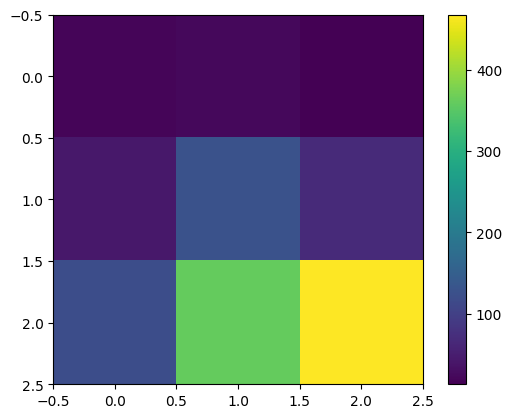

In [52]:
shw = plt.imshow(confusion)
bar = plt.colorbar(shw)
#focus sulla diagonale

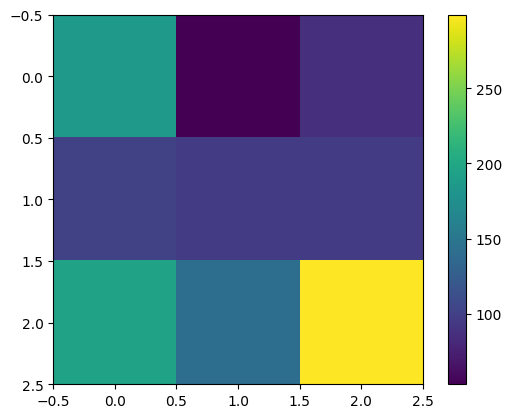

In [53]:
shw = plt.imshow(confusion_ss)
bar = plt.colorbar(shw)
#focus sulla diagonale

In [54]:
accuracy_3_class = np.sum(np.diag(confusion)) / np.sum(confusion.values)
accuracy_3_class

np.float64(0.49637389202256244)

In [55]:
accuracy_3_class_ss = np.sum(np.diag(confusion_ss)) / np.sum(confusion_ss.values)
accuracy_3_class_ss

np.float64(0.46294820717131474)

In [56]:
confusion_2_class = confusion.iloc[[0, 2], [0, 2]] #beware!
confusion_2_class

afinn,-1.0,1.0
sentiment_gold,,
-1,20,13
1,120,468


In [57]:
accuracy_2_class = np.sum(np.diag(confusion_2_class)) / np.sum(confusion_2_class.values)
accuracy_2_class

np.float64(0.785829307568438)

In [58]:
accuracy_2_class_baseline = confusion_2_class.sum().max() / np.sum(confusion_2_class.values)
print(accuracy_2_class_baseline)

0.7745571658615137


### TOKEN

In [59]:
import re

def clean_tweet(text):
    # Rimuove menzioni tipo @user
    text = re.sub(r'@\w+', '', text)
    
    # Rimuove retweet all'inizio (es. "RT @user: ...")
    text = re.sub(r'\brt\b', '', text, flags=re.IGNORECASE)
    
    # Rimuove URL (http, https, www)
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    
    # Rimuove doppie spaziature create
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text


In [60]:
tweet_deadpool['tweet_text'] = tweet_deadpool['tweet_text'].astype(str).apply(clean_tweet)
tweet_suicide['tweet_text'] = tweet_suicide['tweet_text'].astype(str).apply(clean_tweet)

In [61]:
tweet_dp=tweet_deadpool['tweet_text']
tweet_ss = tweet_suicide['tweet_text']
tweet_dp

3       Really hope Deadpool is still showing when I g...
4                    deadpool here, deadpool there. okay.
5       : Last night at the #deadpool premiere #NYC #b...
6       Am I trippin or does it look like Red skull in...
7                                       DEADPOOL tomorrow
                              ...                        
1492    now i know why was was so full of praise about...
1494    Need a gf to come smoke these j's with me and ...
1496        dont go so we can get high and watch deadpool
1497             deadpool after i take the fam out to eat
1498    Deadpool the perfect movie for Valentine's Day...
Name: tweet_text, Length: 1241, dtype: object

In [62]:
tweet_deadpool

,tweet_id,tweet_text,sentiment_gold,afinn_class,afinn
3,697035441153953792,Really hope Deadpool is still showing when I g...,1,Positive,2.0
4,697038361857396736,"deadpool here, deadpool there. okay.",0,Neutral,0.0
5,697040884915965953,: Last night at the #deadpool premiere #NYC #b...,1,Positive,8.0
6,697044015825428480,Am I trippin or does it look like Red skull in...,0,Positive,2.0
7,697046818954162176,DEADPOOL tomorrow,1,Neutral,0.0
...,...,...,...,...,...
1492,698933062814605313,now i know why was was so full of praise about...,1,Positive,11.0
1494,698937915338944512,Need a gf to come smoke these j's with me and ...,0,Neutral,0.0
1496,698938462624284672,dont go so we can get high and watch deadpool,1,Neutral,0.0
1497,698938628882493440,deadpool after i take the fam out to eat,0,Neutral,0.0


In [63]:
emoticons_str = r"""
    (?:
        [:=;] # Eyes
        [oO\-]? # Nose (optional)
        [D\)\]\(\]/\\OpP] # Mouth
    )"""

regex_str = [
    emoticons_str,
    r'<[^>]+>', # HTML tags
    r'(?:@[\w_]+)', # @-mentions
    r"(?:\#+[\w_]+[\w\'_\-]*[\w_]+)", # hash-tags
    r'http[s]?://(?:[a-z]|[0-9]|[$-_@.&amp;+]|[!*\(\),]|(?:%[0-9a-f][0-9a-f]))+', # URLs
    r'(?:(?:\d+,?)+(?:\.?\d+)?)', # numbers
    r"(?:[a-z][a-z'\-_]+[a-z])", # words with - and '
    r'(?:[\w_]+)', # other words
    r'(?:\S)' # anything else
]

tokens_re = re.compile(r'('+'|'.join(regex_str)+')', re.VERBOSE | re.IGNORECASE)
emoticon_re = re.compile(r'^'+emoticons_str+'$', re.VERBOSE | re.IGNORECASE)

def tokenize(s):
    return tokens_re.findall(s)

def preprocess(s, lowercase=True): #custom function
    tokens = tokenize(s)
    if lowercase:
        tokens = [token if emoticon_re.search(token) else token.lower() for token in tokens]
    return tokens

In [64]:
tweet_dp.apply(preprocess)

3       [really, hope, deadpool, is, still, showing, w...
4        [deadpool, here, ,, deadpool, there, ., okay, .]
5       [:, last, night, at, the, #deadpool, premiere,...
6       [am, i, trippin, or, does, it, look, like, red...
7                                    [deadpool, tomorrow]
                              ...                        
1492    [now, i, know, why, was, was, so, full, of, pr...
1494    [need, a, gf, to, come, smoke, these, j's, wit...
1496    [dont, go, so, we, can, get, high, and, watch,...
1497    [deadpool, after, i, take, the, fam, out, to, ...
1498    [deadpool, the, perfect, movie, for, valentine...
Name: tweet_text, Length: 1241, dtype: object

In [65]:
tweet_ss.apply(preprocess)

1500    [:, it, was, interesting, looking, for, a, plo...
1501    [:, we're, going, on, a, field, trip, !, !, #s...
1502    [:, i, need, those, cut, scenes, of, the, #jok...
1503    [:, #suicidesquad, destroys, august, record, w...
1504    [:, #suicidesquad, continued, the, trend, of, ...
                              ...                        
2993    [:, heading, in, to, see, #suicidesquad, wish,...
2994    [:, #suicidesquad, expected, to, make, 38, -, ...
2995    [:, well, that, was, horrifically, bad, ., i'm...
2996            [:, i, need, to, watch, #suicidesquad, !]
2997    [:, and, that, was, #suicidesquad, ., ., ., go...
Name: tweet_text, Length: 1255, dtype: object

In [66]:
tweet_dp = tweet_dp.apply(lambda x: x.lower())
tweet_ss = tweet_ss.apply(lambda x: x.lower())
tweet_dp

3       really hope deadpool is still showing when i g...
4                    deadpool here, deadpool there. okay.
5       : last night at the #deadpool premiere #nyc #b...
6       am i trippin or does it look like red skull in...
7                                       deadpool tomorrow
                              ...                        
1492    now i know why was was so full of praise about...
1494    need a gf to come smoke these j's with me and ...
1496        dont go so we can get high and watch deadpool
1497             deadpool after i take the fam out to eat
1498    deadpool the perfect movie for valentine's day...
Name: tweet_text, Length: 1241, dtype: object

In [67]:
from nltk.tokenize import TweetTokenizer
tokening = TweetTokenizer()
tokening = TweetTokenizer(strip_handles=True, reduce_len=True)
tweet_tokenized = tweet_dp.apply(TweetTokenizer().tokenize)
tweet_tokenized
tweet_tokenized_ss = tweet_ss.apply(TweetTokenizer().tokenize)
tweet_tokenized_ss

1500    [:, it, was, interesting, looking, for, a, plo...
1501    [:, we're, going, on, a, field, trip, !, !, #s...
1502    [:, i, need, those, cut, scenes, of, the, #jok...
1503    [:, #suicidesquad, destroys, august, record, w...
1504    [:, #suicidesquad, continued, the, trend, of, ...
                              ...                        
2993    [:, heading, in, to, see, #suicidesquad, wish,...
2994    [:, #suicidesquad, expected, to, make, 38-42, ...
2995    [:, well, that, was, horrifically, bad, ., i'm...
2996            [:, i, need, to, watch, #suicidesquad, !]
2997    [:, and, that, was, #suicidesquad, ..., good, ...
Name: tweet_text, Length: 1255, dtype: object

In [68]:
# Function to get the counter (will be helpful later on)
def get_counter(series):
  flat_list = [item for sublist in series for item in sublist]
  c = Counter(flat_list)
  return c

### STOPWORDS

In [69]:
from nltk.corpus import stopwords
stop = stopwords.words('english') #important!
stop = [item for item in stop if item not in ["not", "nor", "against"]]
stop

['a',
 'about',
 'above',
 'after',
 'again',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'only',
 'or',
 'other',
 'our'

In [70]:
tweet_tokenized_stop = tweet_tokenized.apply(lambda x: [item for item in x if item not in stop])
tweet_tokenized_stop


3       [really, hope, deadpool, still, showing, get, ...
4                     [deadpool, ,, deadpool, ., okay, .]
5       [:, last, night, #deadpool, premiere, #nyc, #b...
6       [trippin, look, like, red, skull, deadpool, tr...
7                                    [deadpool, tomorrow]
                              ...                        
1492    [know, full, praise, deadpool, great, film, on...
1494          [need, gf, come, smoke, j's, see, deadpool]
1496               [dont, go, get, high, watch, deadpool]
1497                           [deadpool, take, fam, eat]
1498    [deadpool, perfect, movie, valentine's, day, !...
Name: tweet_text, Length: 1241, dtype: object

In [71]:
tweet_tokenized_stop_ss = tweet_tokenized_ss.apply(lambda x: [item for item in x if item not in stop])
tweet_tokenized_stop_ss

1500    [:, interesting, looking, plot, different, hol...
1501         [:, going, field, trip, !, !, #suicidesquad]
1502    [:, need, cut, scenes, #joker, bluray, !, #sui...
1503    [:, #suicidesquad, destroys, august, record, $...
1504    [:, #suicidesquad, continued, trend, blue, bea...
                              ...                        
2993    [:, heading, see, #suicidesquad, wish, luck, ....
2994    [:, #suicidesquad, expected, make, 38-42, week...
2995    [:, well, horrifically, bad, ., almost, impres...
2996                   [:, need, watch, #suicidesquad, !]
2997    [:, #suicidesquad, ..., good, actors, stuck, b...
Name: tweet_text, Length: 1255, dtype: object

### PUNTEGGIATURA

In [72]:
import string
from nltk import wordpunct_tokenize

punctuation = string.punctuation #string library
print(punctuation)

!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~


In [73]:
tweet_tokenized_stop_punct = tweet_tokenized_stop.apply(lambda x: [item for item in x if item not in punctuation])
tweet_tokenized_stop_punct

3       [really, hope, deadpool, still, showing, get, ...
4                              [deadpool, deadpool, okay]
5       [last, night, #deadpool, premiere, #nyc, #beau...
6       [trippin, look, like, red, skull, deadpool, tr...
7                                    [deadpool, tomorrow]
                              ...                        
1492    [know, full, praise, deadpool, great, film, on...
1494          [need, gf, come, smoke, j's, see, deadpool]
1496               [dont, go, get, high, watch, deadpool]
1497                           [deadpool, take, fam, eat]
1498    [deadpool, perfect, movie, valentine's, day, #...
Name: tweet_text, Length: 1241, dtype: object

In [74]:
tweet_tokenized_stop_punct_ss = tweet_tokenized_stop_ss.apply(lambda x: [item for item in x if item not in punctuation])
tweet_tokenized_stop_punct_ss

1500    [interesting, looking, plot, different, holes,...
1501                  [going, field, trip, #suicidesquad]
1502    [need, cut, scenes, #joker, bluray, #suicidesq...
1503    [#suicidesquad, destroys, august, record, 135,...
1504    [#suicidesquad, continued, trend, blue, beam, ...
                              ...                        
2993    [heading, see, #suicidesquad, wish, luck, #dcc...
2994    [#suicidesquad, expected, make, 38-42, weekend...
2995    [well, horrifically, bad, almost, impressed, #...
2996                         [need, watch, #suicidesquad]
2997    [#suicidesquad, ..., good, actors, stuck, bad,...
Name: tweet_text, Length: 1255, dtype: object

In [75]:
stop = set(stop)
#adding some of the stopwords after observing the tweets
stop.add("The")
stop.add("And")
stop.add("I")
stop.add("J")
stop.add("K")
stop.add("I'd")
stop.add("That's")
stop.add("\x81")
stop.add("It")
stop.add("I'm")
stop.add("...")
stop.add("\x89")
stop.add("ĚĄ")
stop.add("it's")
stop.add("ă")
stop.add("\x9d")
stop.add("âÂĺ")
stop.add("Ě")
stop.add("˘")
stop.add("Â")
stop.add("âÂ")
stop.add("Ň")
stop.add("http")
stop.add("https")
stop.add("co")
stop.add("000")
stop.add("Ň")
stop.add("Ň")
stop.add("Ň")
stop.add("ââ")
stop.add('ě')
stop.add('ň')
stop.add('ââĺ')

stop = list(stop)
print(stop)

tweet_tokenized_stop_punct = tweet_tokenized_stop_punct.apply(lambda x: [item for item in x if item not in stop])
tweet_tokenized_stop_punct
tweet_tokenized_stop_punct_ss = tweet_tokenized_stop_punct_ss.apply(lambda x: [item for item in x if item not in stop])
tweet_tokenized_stop_punct_ss

["didn't", 'hasn', 'only', 'to', 'themselves', "they'll", 'when', 'mightn', 'yours', 'where', 'hadn', 'do', "she's", 'each', "it'll", "that'll", 'before', 'ââĺ', "couldn't", 'during', 'shouldn', "weren't", 'there', 'why', "i'd", 'theirs', 'The', "won't", 'here', 'which', 's', 't', 'the', "isn't", "we'd", 'itself', 'K', 'after', 'these', "he'll", 'be', 'a', "doesn't", '000', 'It', 'our', 'himself', 'are', 'such', 'while', 'further', 'once', 'won', "I'd", 'wouldn', 'And', 'co', 'been', "i'm", 'them', 'own', 'or', "I'm", 'an', 'below', 'her', 'ââ', "should've", 'doesn', 'I', 'haven', 'mustn', 'needn', 'up', 'for', 'now', 'ň', 'just', 'of', '\x81', "they'd", 'hers', 'through', 'this', 'until', "it'd", 'than', 'they', 'because', 'on', 'then', 'have', 'does', 'couldn', 'who', "That's", 'https', 'Ě', 'âÂ', 'and', 'above', 'over', 'your', 'his', 'from', 'o', 'my', 'all', "aren't", 'she', "you're", '˘', 'more', 'how', 'few', "hadn't", 'me', 'about', 'herself', "you've", 'shan', 'that', 'by', 'h

1500    [interesting, looking, plot, different, holes,...
1501                  [going, field, trip, #suicidesquad]
1502    [need, cut, scenes, #joker, bluray, #suicidesq...
1503    [#suicidesquad, destroys, august, record, 135,...
1504    [#suicidesquad, continued, trend, blue, beam, ...
                              ...                        
2993    [heading, see, #suicidesquad, wish, luck, #dcc...
2994    [#suicidesquad, expected, make, 38-42, weekend...
2995    [well, horrifically, bad, almost, impressed, #...
2996                         [need, watch, #suicidesquad]
2997    [#suicidesquad, good, actors, stuck, bad, scri...
Name: tweet_text, Length: 1255, dtype: object

### LEMMA

In [76]:
!pip install spacy


In [77]:
import spacy

nlp = spacy.load("en_core_web_sm") 

def lemmatize(text):
    doc = nlp(text)
    return " ".join([token.lemma_ for token in doc if not token.is_punct and not token.is_space])

# Applica la lemmatizzazione 
lemma_tweet= tweet_tokenized_stop_punct.astype(str).apply(lemmatize)
lemma_tweet_ss= tweet_tokenized_stop_punct_ss.astype(str).apply(lemmatize)


In [78]:
lemma_tweet_token = lemma_tweet.apply(TweetTokenizer().tokenize)
lemma_tweet_token

3       [really, hope, deadpool, still, show, get, bac...
4                              [deadpool, deadpool, okay]
5       [last, night, deadpool, premiere, nyc, beauty,...
6       [trippin, look, like, red, skull, deadpool, tr...
7                                    [deadpool, tomorrow]
                              ...                        
1492    [know, full, praise, deadpool, great, film, on...
1494      [need, gf, come, smoke, j, ', s, see, deadpool]
1496            [do, not, go, get, high, watch, deadpool]
1497                           [deadpool, take, fam, eat]
1498    [deadpool, perfect, movie, valentine, ', s, da...
Name: tweet_text, Length: 1241, dtype: object

In [79]:
lemma_tweet_token_ss = lemma_tweet_ss.apply(TweetTokenizer().tokenize)
lemma_tweet_token_ss

1500    [interesting, look, plot, different, hole, sui...
1501                      [go, field, trip, suicidesquad]
1502      [need, cut, scene, joker, bluray, suicidesquad]
1503    [suicidesquad, destroy, august, record, 135, m...
1504    [suicidesquad, continue, trend, blue, beam, sh...
                              ...                        
2993       [head, see, suicidesquad, wish, luck, dccomic]
2994    [suicidesquad, expect, make, 38, 42, weekend, ...
2995    [well, horrifically, bad, almost, impressed, s...
2996                          [need, watch, suicidesquad]
2997    [suicidesquad, good, actor, stuck, bad, script...
Name: tweet_text, Length: 1255, dtype: object

In [80]:
import matplotlib.pyplot as plt
%matplotlib inline
from PIL import Image
import numpy as np

from wordcloud import WordCloud

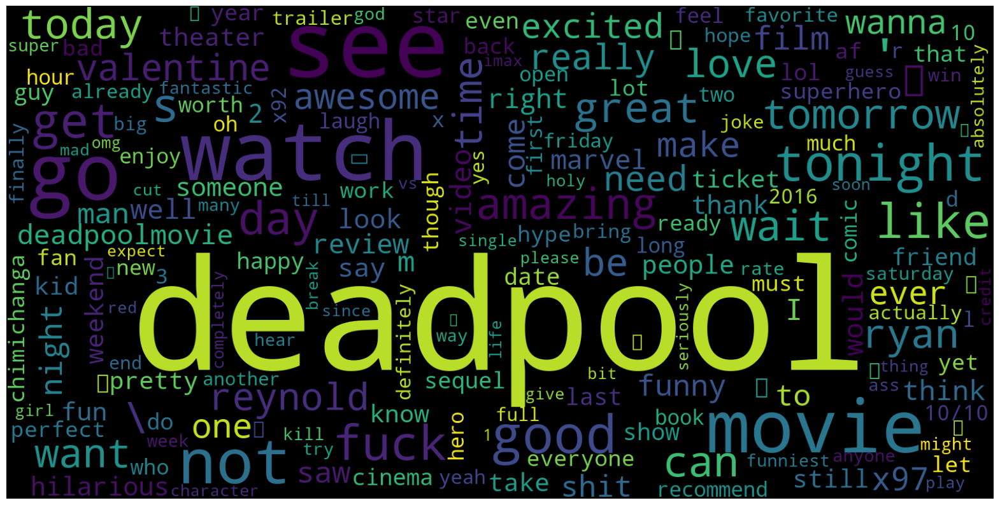

In [81]:
flat_list = [item for sublist in lemma_tweet_token for item in sublist] #unique list containing all tokens

fig = plt.figure(figsize=(20,14))
wordcloud = WordCloud(width=1600, height=800, background_color="black").generate_from_frequencies(Counter(flat_list))
plt.axis("off")
plt.imshow(wordcloud, interpolation='antialiased')

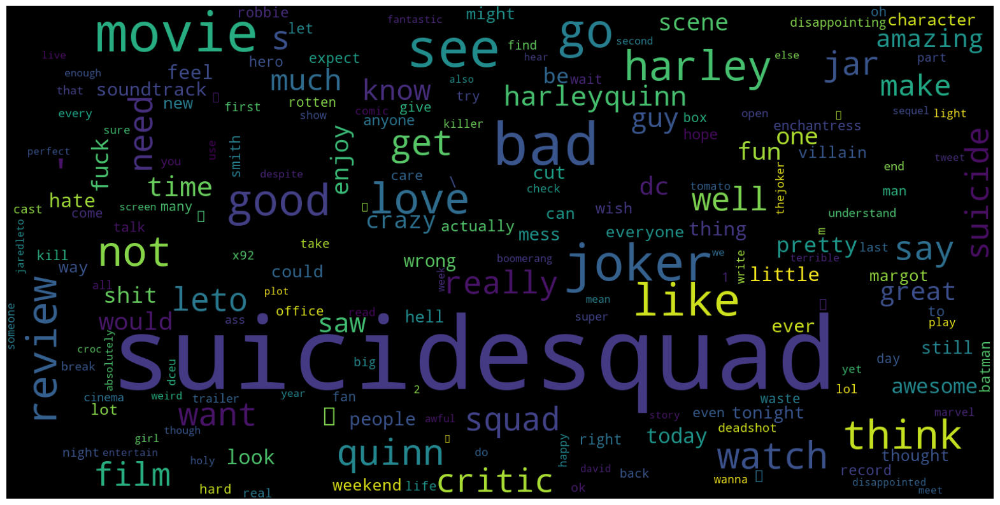

In [82]:
flat_list = [item for sublist in lemma_tweet_token_ss for item in sublist] #unique list containing all tokens

fig = plt.figure(figsize=(20,14))
wordcloud = WordCloud(width=1600, height=800, background_color="black").generate_from_frequencies(Counter(flat_list))
plt.axis("off")
plt.imshow(wordcloud, interpolation='antialiased')

## ML

In [83]:
tweet_deadpool['tweet_text'] = lemma_tweet_token.apply(lambda tokens: " ".join(tokens))
tweet_deadpool
tweet_suicide['tweet_text'] = lemma_tweet_token_ss.apply(lambda tokens: " ".join(tokens))
tweet_suicide

,tweet_id,tweet_text,sentiment_gold,afinn_class,afinn
1500,762317617604558848,interesting look plot different hole suicidesq...,-1,Positive,2.0
1501,762317861536661505,go field trip suicidesquad,1,Neutral,0.0
1502,762318029338255360,need cut scene joker bluray suicidesquad,1,Negative,-1.0
1503,762318073613484032,suicidesquad destroy august record 135 million...,1,Negative,-3.0
1504,762318444679274496,suicidesquad continue trend blue beam shoot sk...,-1,Neutral,0.0
...,...,...,...,...,...
2993,764504551714066432,head see suicidesquad wish luck dccomic,0,Positive,4.0
2994,764507578269310976,suicidesquad expect make 38 42 weekend 135 m o...,1,Positive,4.0
2995,764509349674749954,well horrifically bad almost impressed suicide...,-1,Neutral,0.0
2996,764514512762535936,need watch suicidesquad,1,Neutral,0.0


In [84]:
# It is possible to specify different parameters, e.g. stopwords, lowercase
from sklearn.feature_extraction.text import CountVectorizer

count_vect = CountVectorizer(stop_words=None, lowercase=True, max_features=5000)
#https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html
#stopwords were already removed in tweets_tokenized_new_stem

#to create the bag of words (bow)
#fit_transform takes as input  full sententeces NOT token
#so, the join function combines sparated tokens including spaces " "
bow = count_vect.fit_transform(lemma_tweet_token.apply(lambda x: " ".join(x)))
bow_ss = count_vect.fit_transform(lemma_tweet_token_ss.apply(lambda x: " ".join(x)))
#fit and transform functions can be separated

print(len(lemma_tweet_token))
print(bow.shape)
print(bow.toarray())
print(len(lemma_tweet_token_ss))
print(bow_ss.shape)
print(bow_ss.toarray())

1241
(1241, 1951)
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
1255
(1255, 1962)
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [85]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test  = train_test_split(
        bow.toarray(),
        tweet_deadpool.sentiment_gold,
        train_size=0.80,
        random_state=1234)

In [86]:

X_trainss, X_testss, y_trainss, y_testss  = train_test_split(
        bow_ss.toarray(),
        tweet_suicide.sentiment_gold,
        train_size=0.80,
        random_state=1234)

In [87]:
from sklearn.linear_model import LogisticRegression
log_model = LogisticRegression(max_iter=250, class_weight='balanced')
log_model = log_model.fit(X=X_train, y=y_train)

In [88]:
log_modelss = LogisticRegression(max_iter=250, class_weight='balanced')
log_modelss = log_modelss.fit(X=X_trainss, y=y_trainss)

In [89]:
y_pred = log_model.predict(X_test)
print(y_pred) #predicted sentiment

[ 1  1  1  1  1  0  1  0  0  1  1  1  0  1  1  1  1  0  0  1  1  1  1  1
  0  1  1  0  1  1  1  0  1  0  1  1  1  1  0  0  1  0  1  1  1  1  1  0
  0  1  1  0  1  1  0  1  1  1  1  1  1  1  0  1  1  1  1  1  1  1  1  1
  1  1 -1  1  1  0  0  0  0  1  1  1  0  1  1  0  1  1  1  1  1  1  1  1
  0  1  0  0  0  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  0  0
  1  1  1  1  1  1  1  1  0  1  1  0  0  1  1  1  1  1  1  0  1  1  1  1
  1  1  1  1  1  1  1  0  1  1  1  1  0  0  1  1  0 -1  1  0  1  1  1  0
  1  1  1  1  1  1  1  1  1  1  1  0  1  1  1  1 -1  1  0  1  0  1  0  1
  1  1  1  1  0  0  0  0  1  1  1  1  1  1  1  0  1  0  1  1  1  1  1  0
  0  1  1  1  1  0  1  1  0  1  1  1  1 -1  1 -1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1]


In [90]:
y_predss = log_modelss.predict(X_testss)
print(y_predss) #predicted sentiment

[-1 -1  1  1  0  0  1 -1  1  0  1  0  0 -1  1  1 -1  0  1  1  0  1  0  1
  1  0  0  1  0  1  1 -1  1  1  0  0 -1  1  0  1  1  0  1 -1  1  0 -1  0
  1  0  1  1  1  1  1  0  0 -1  0 -1  1  0  1  1  0  1  1  1  1  1  1  1
 -1  1  0  0  1  1 -1  0  0 -1  1  0  1  1  1  1 -1  0 -1  0 -1  0  0 -1
  0  1 -1  1  0  0 -1  1 -1 -1  1 -1  1  1  0  1 -1  0  1  1  0  1  1  1
  0 -1 -1 -1  1  0  1  1  0  0  1  0  1 -1 -1  1  1  0  1  1  1  0 -1  0
  1 -1  1 -1  0  1  0  1  0  0 -1 -1  1  1  1  0  1  1  1  0  1  1  1 -1
  1  0  1  0  0  1  1 -1  1 -1  1  1 -1  0  1  0 -1  0 -1  0  1  1  1 -1
  0  1  0  1  1  1  1  0 -1  0 -1  1  1  0  1  0  1  1  1  1  1  1  1  0
  1  0  0  1 -1  1 -1  1 -1 -1 -1  1  1  1  1  1 -1  0 -1  0  0  0 -1  1
  1 -1  1 -1 -1  1  1  1  1  1  0]


In [91]:
from sklearn.metrics import accuracy_score
print(accuracy_score(y_test, y_pred))
print(accuracy_score(y_testss, y_predss))

0.7188755020080321
0.5219123505976095


In [92]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))
print(classification_report(y_testss, y_predss))

              precision    recall  f1-score   support

          -1       0.20      0.08      0.12        12
           0       0.33      0.42      0.37        43
           1       0.84      0.82      0.83       194

    accuracy                           0.72       249
   macro avg       0.46      0.44      0.44       249
weighted avg       0.72      0.72      0.72       249

              precision    recall  f1-score   support

          -1       0.54      0.45      0.49        64
           0       0.32      0.41      0.36        56
           1       0.64      0.60      0.62       131

    accuracy                           0.52       251
   macro avg       0.50      0.49      0.49       251
weighted avg       0.54      0.52      0.53       251



In [93]:
#la classe negativa è rappresentata pochissimo in dedapool

In [94]:
from sklearn.model_selection import cross_val_score
clf = LogisticRegression(max_iter = 250)
scores = cross_val_score(clf, bow.toarray(), tweet_deadpool.sentiment_gold, cv=3)

clf_ss = LogisticRegression(max_iter = 250)
scores_ss = cross_val_score(clf_ss, bow_ss.toarray(), tweet_suicide.sentiment_gold, cv=3)

In [95]:
print(scores)
print("Accuracy: %0.2f (+/- %0.2f)" % (scores.mean(), scores.std() * 2))

print(scores_ss)
print("Accuracy: %0.2f (+/- %0.2f)" % (scores_ss.mean(), scores_ss.std() * 2))

[0.74396135 0.73671498 0.75786925]
Accuracy: 0.75 (+/- 0.02)
[0.53937947 0.59090909 0.5861244 ]
Accuracy: 0.57 (+/- 0.05)


In [96]:
accuracy_dp_logregr=scores.mean()
accuracy_ss_logregr=scores_ss.mean()

In [97]:
tweet_deadpool

,tweet_id,tweet_text,sentiment_gold,afinn_class,afinn
3,697035441153953792,really hope deadpool still show get back engla...,1,Positive,2.0
4,697038361857396736,deadpool deadpool okay,0,Neutral,0.0
5,697040884915965953,last night deadpool premiere nyc beauty chelse...,1,Positive,8.0
6,697044015825428480,trippin look like red skull deadpool trailer b...,0,Positive,2.0
7,697046818954162176,deadpool tomorrow,1,Neutral,0.0
...,...,...,...,...,...
1492,698933062814605313,know full praise deadpool great film one good ...,1,Positive,11.0
1494,698937915338944512,need gf come smoke j ' s see deadpool,0,Neutral,0.0
1496,698938462624284672,do not go get high watch deadpool,1,Neutral,0.0
1497,698938628882493440,deadpool take fam eat,0,Neutral,0.0


In [98]:
tweet_suicide

,tweet_id,tweet_text,sentiment_gold,afinn_class,afinn
1500,762317617604558848,interesting look plot different hole suicidesq...,-1,Positive,2.0
1501,762317861536661505,go field trip suicidesquad,1,Neutral,0.0
1502,762318029338255360,need cut scene joker bluray suicidesquad,1,Negative,-1.0
1503,762318073613484032,suicidesquad destroy august record 135 million...,1,Negative,-3.0
1504,762318444679274496,suicidesquad continue trend blue beam shoot sk...,-1,Neutral,0.0
...,...,...,...,...,...
2993,764504551714066432,head see suicidesquad wish luck dccomic,0,Positive,4.0
2994,764507578269310976,suicidesquad expect make 38 42 weekend 135 m o...,1,Positive,4.0
2995,764509349674749954,well horrifically bad almost impressed suicide...,-1,Neutral,0.0
2996,764514512762535936,need watch suicidesquad,1,Neutral,0.0


#### TF_IDF

In [99]:
# Dividiamo i testi per classe di sentiment
text_pos_dp = tweet_deadpool[tweet_deadpool['sentiment_gold'] == 1]['tweet_text']
text_neg_dp = tweet_deadpool[tweet_deadpool['sentiment_gold'] == -1]['tweet_text']
text_neu_dp = tweet_deadpool[tweet_deadpool['sentiment_gold'] == 0]['tweet_text']

text_pos_ss = tweet_suicide[tweet_suicide['sentiment_gold'] == 1]['tweet_text']
text_neg_ss = tweet_suicide[tweet_suicide['sentiment_gold'] == -1]['tweet_text']
text_neu_ss = tweet_suicide[tweet_suicide['sentiment_gold'] == 0]['tweet_text']


In [100]:
text_pos_dp = " ".join(text_pos_dp)
text_neg_dp = " ".join(text_neg_dp)
text_neu_dp= " ".join(text_neu_dp)

text_pos_ss = " ".join(text_pos_ss)
text_neg_ss = " ".join(text_neg_ss)
text_neu_ss= " ".join(text_neu_ss)


In [101]:
# Tfidf su tutti i tweet individuali
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=500)
X = vectorizer.fit_transform(tweet_deadpool['tweet_text'])
Y = vectorizer.fit_transform(tweet_suicide['tweet_text'])

# Colonne = parole, righe = tweet
tfidf_df = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())
tfidf_df_ss = pd.DataFrame(Y.toarray(), columns=vectorizer.get_feature_names_out())



In [102]:
tweet_deadpool['sentiment_gold'] = tweet_deadpool['sentiment_gold'].astype(int)
tfidf_df['sentiment'] = tweet_deadpool['sentiment_gold'].values

# Calcola media tf-idf per classe
mean_pos = tfidf_df[tfidf_df['sentiment'] == 1].drop('sentiment', axis=1).mean()
mean_neg = tfidf_df[tfidf_df['sentiment'] == -1].drop('sentiment', axis=1).mean()
mean_neu = tfidf_df[tfidf_df['sentiment'] == 0].drop('sentiment', axis=1).mean()

# Prendi le top parole distintive
print("🔝 Parole tipiche positive:")
print(mean_pos.sort_values(ascending=False).head(10))

print("\n🔝 Parole tipiche negative:")
print(mean_neg.sort_values(ascending=False).head(10))


🔝 Parole tipiche positive:
diablo      0.144431
seem        0.057740
wait        0.055822
get         0.045267
may         0.041367
together    0.029002
ass         0.028901
four        0.027753
give        0.026906
near        0.024088
dtype: float64

🔝 Parole tipiche negative:
diablo        0.107364
near          0.059281
seem          0.050226
get           0.048478
ridiculous    0.034489
check         0.034449
feel          0.032540
right         0.032100
sad           0.031397
wish          0.030640
dtype: float64


In [103]:
tweet_suicide['sentiment_gold'] = tweet_suicide['sentiment_gold'].astype(int)
tfidf_df_ss['sentiment'] = tweet_suicide['sentiment_gold'].values

# Calcola media tf-idf per classe
mean_pos_ss = tfidf_df_ss[tfidf_df_ss['sentiment'] == 1].drop('sentiment', axis=1).mean()
mean_neg_ss = tfidf_df_ss[tfidf_df_ss['sentiment'] == -1].drop('sentiment', axis=1).mean()
mean_neu_ss = tfidf_df_ss[tfidf_df_ss['sentiment'] == 0].drop('sentiment', axis=1).mean()

# Prendi le top parole distintive
print("🔝 Parole tipiche positive:")
print(mean_pos_ss.sort_values(ascending=False).head(10))

print("\n🔝 Parole tipiche negative:")
print(mean_neg_ss.sort_values(ascending=False).head(10))


🔝 Parole tipiche positive:
suicidesquad    0.106335
bad             0.046600
see             0.045561
love            0.042281
movie           0.040615
joker           0.036880
go              0.033692
good            0.031506
harley          0.031395
like            0.030076
dtype: float64

🔝 Parole tipiche negative:
suicidesquad    0.100574
bad             0.058187
movie           0.048379
not             0.034252
like            0.032428
joker           0.032335
film            0.031664
review          0.028074
see             0.025142
think           0.024778
dtype: float64


In [104]:
parole_da_escludere = {'see', 'go', 'watch', 'movie', 'film', 'deadpool', 'suicidesquad' , 'suicide', 'squad' , 'character', 'actor'}

# Rimuovi parole dalla serie TF-IDF
mean_pos_clean = mean_pos[~mean_pos.index.isin(parole_da_escludere)]
mean_neg_clean = mean_neg[~mean_neg.index.isin(parole_da_escludere)]
mean_neu_clean = mean_neu[~mean_neu.index.isin(parole_da_escludere)]

mean_pos_cleanss = mean_pos_ss[~mean_pos_ss.index.isin(parole_da_escludere)]
mean_neg_cleanss = mean_neg_ss[~mean_neg_ss.index.isin(parole_da_escludere)]
mean_neu_cleanss = mean_neu_ss[~mean_neu_ss.index.isin(parole_da_escludere)]

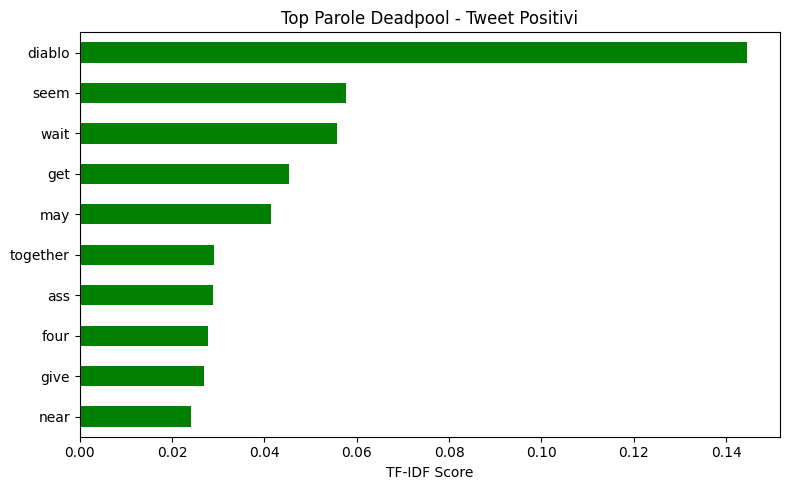

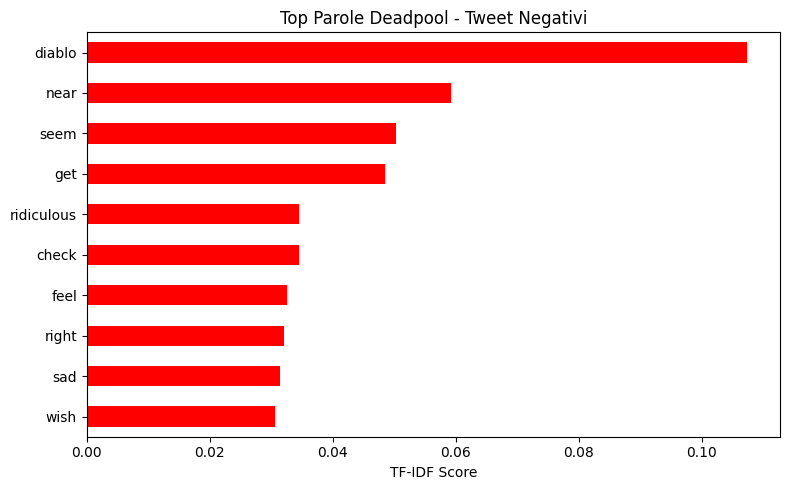

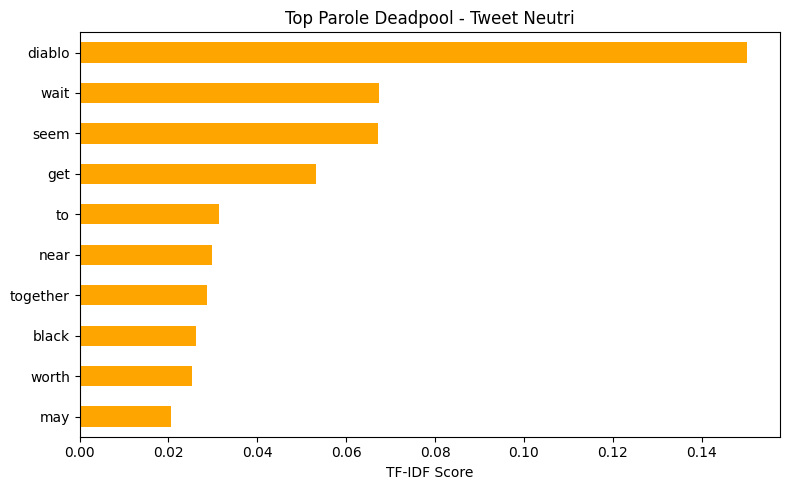

In [105]:
def plot_top_words(tfidf_series, title, color):
    tfidf_series.sort_values(ascending=True).tail(10).plot(kind='barh', color=color, figsize=(8,5))
    plt.title(title)
    plt.xlabel("TF-IDF Score")
    plt.tight_layout()
    plt.show()

plot_top_words(mean_pos_clean, "Top Parole Deadpool - Tweet Positivi", 'green')
plot_top_words(mean_neg_clean, "Top Parole Deadpool - Tweet Negativi", 'red')
plot_top_words(mean_neu_clean, "Top Parole Deadpool - Tweet Neutri", 'orange')


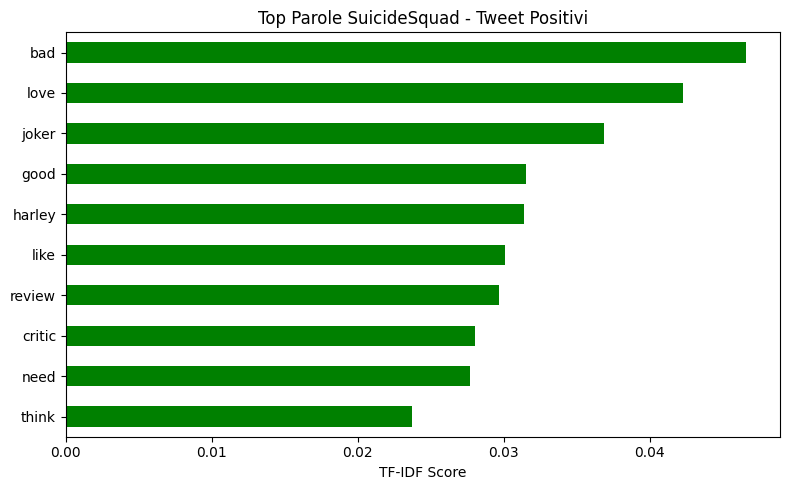

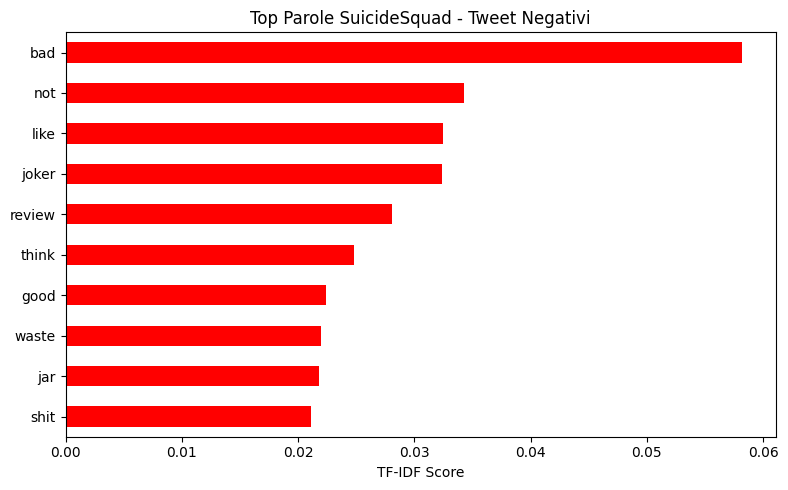

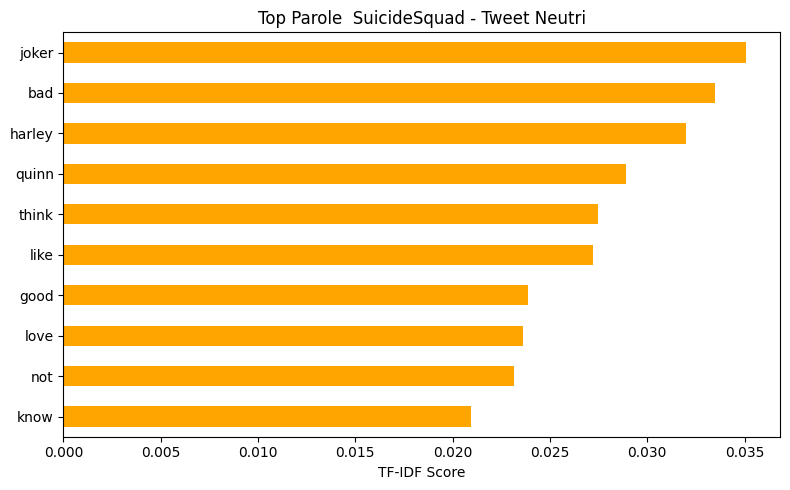

In [106]:
plot_top_words(mean_pos_cleanss, "Top Parole SuicideSquad - Tweet Positivi", 'green')
plot_top_words(mean_neg_cleanss, "Top Parole SuicideSquad - Tweet Negativi", 'red')
plot_top_words(mean_neu_cleanss, "Top Parole  SuicideSquad - Tweet Neutri", 'orange')


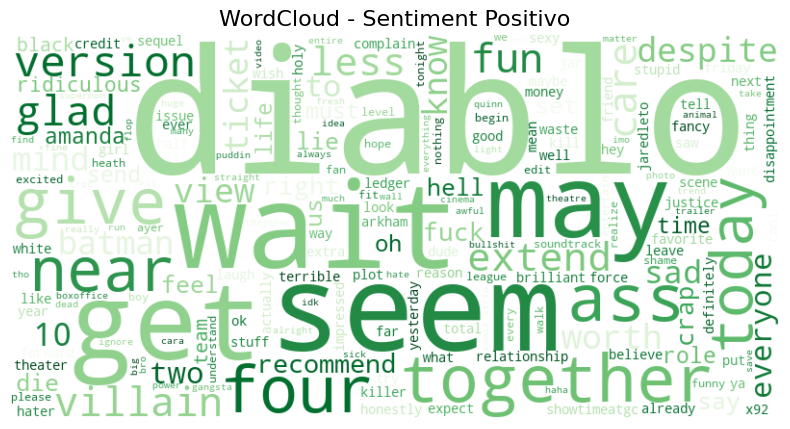

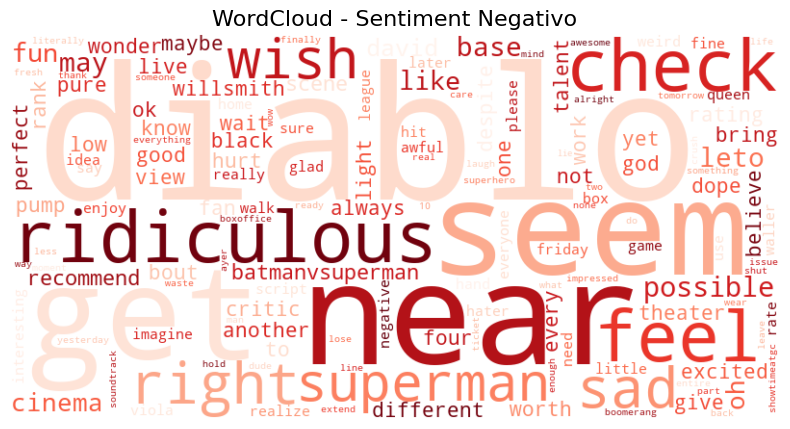

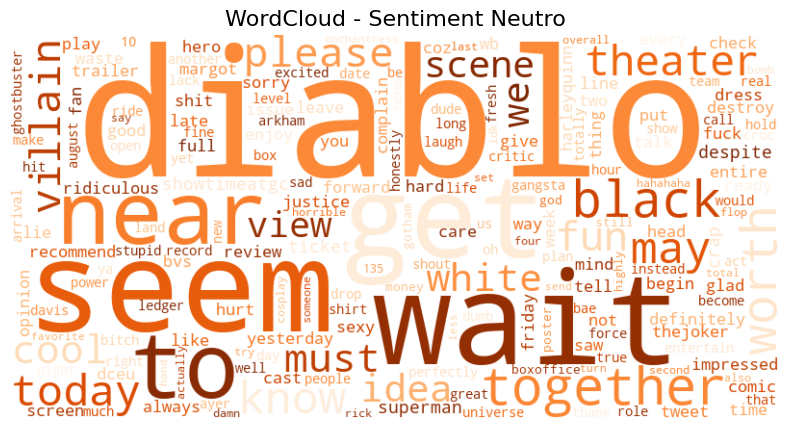

In [108]:
import os
def show_tfidf_wordcloud(tfidf_series, title, colormap,name_image):
    wordcloud = WordCloud(width=800, height=400, background_color='white',
                          colormap=colormap).generate_from_frequencies(tfidf_series.to_dict())
    plt.figure(figsize=(10,5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(title, fontsize=16)
    save_path = os.path.join("assets", name_image)
    plt.savefig(save_path, bbox_inches='tight')
    plt.show()

# Wordcloud TF-IDF puliti
show_tfidf_wordcloud(mean_pos_clean, "WordCloud - Sentiment Positivo", 'Greens',"wordcloudpositiveDP.png")
show_tfidf_wordcloud(mean_neg_clean, "WordCloud - Sentiment Negativo", 'Reds', "wordcloudnegativeDP.png")
show_tfidf_wordcloud(mean_neu_clean, "WordCloud - Sentiment Neutro", 'Oranges', "wordcloudneutralDP.png")


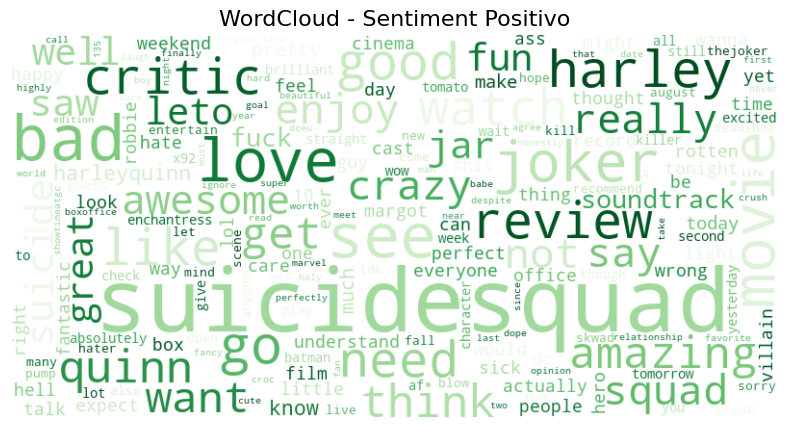

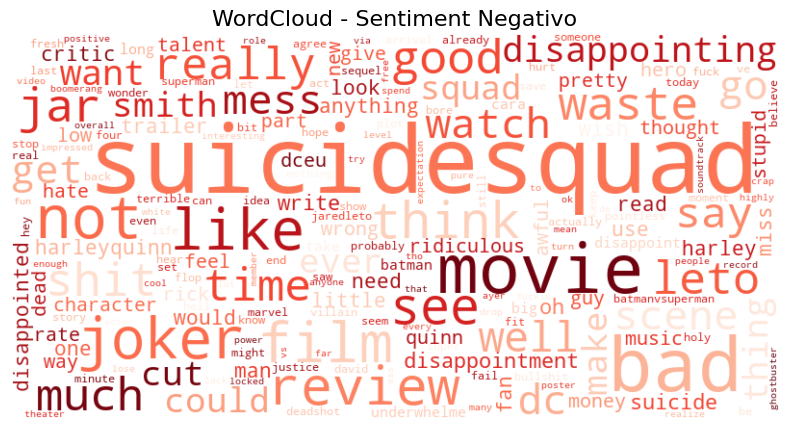

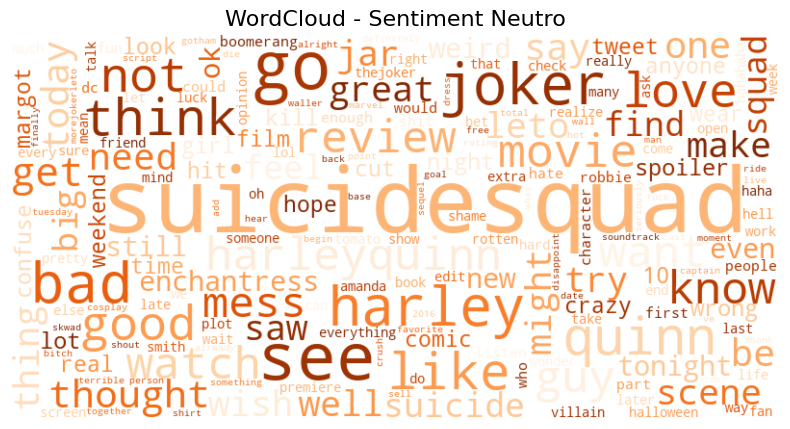

In [109]:
# Wordcloud TF-IDF puliti
show_tfidf_wordcloud(mean_pos_ss, "WordCloud - Sentiment Positivo", 'Greens', "wordcloudpositiveSS.png")
show_tfidf_wordcloud(mean_neg_ss, "WordCloud - Sentiment Negativo", 'Reds', "wordcloudnegativeSS.png")
show_tfidf_wordcloud(mean_neu_ss, "WordCloud - Sentiment Neutro", 'Oranges', "wordcloudneutralSS.png")

In [110]:
import matplotlib.pyplot as plt

def plot_top_words(tfidf_series, title, color, n=10):
    tfidf_series.sort_values(ascending=True).tail(n).plot(
        kind='barh', color=color, figsize=(8, 5))
    plt.title(title, fontsize=14)
    plt.xlabel("TF-IDF Score")
    plt.ylabel("Parola")
    plt.grid(axis='x', linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()


### EMOJI

In [111]:
tweet_deadpool['keyword'] = 'deadpool'
tweet_suicide['keyword'] = 'suicidesquad'

tweet = pd.concat([tweet_deadpool, tweet_suicide], ignore_index=True)

In [112]:
# Unisci emoji (con posizione) al testo del tweet
emoji_merged = emoji.merge(tweet[['tweet_id', 'tweet_text', 'sentiment_gold', 'keyword']], on='tweet_id', how='left')
emoji_merged


,tweet_id,emoji_position,sentiment_gold_x,tweet_text,sentiment_gold_y,keyword
0,697061232810008576,1,Positive,tip watch deadpool watch love one ☺ ️,1.0,deadpool
1,697147578631221249,1,Positive,deadpool friday 😁,1.0,deadpool
2,697156694799970304,1,Negative,read deadpool comic_strip ahead film not reall...,-1.0,deadpool
3,697166947587330048,1,Negative,can not wait watch deadpool 😭,1.0,deadpool
4,697181575344230402,1,Positive,can not wait go see deadpool 👌 🎦 🎥,1.0,deadpool
...,...,...,...,...,...,...
508,764297220753469440,1,Negative,suicidesquad great movie really understand bas...,1.0,suicidesquad
509,764385105653538816,1,Negative,watch suicidesquad last night sad say not impr...,-1.0,suicidesquad
510,764466249053179904,1,Positive,like good love story ever seriously good 😂 sui...,1.0,suicidesquad
511,764475999656435712,1,Positive,movie date crazy suicidesquad 💕 💕,1.0,suicidesquad


In [113]:
emoji_merged.drop(columns=['sentiment_gold_y'],inplace=True)
emoji_merged = emoji_merged.rename(columns={'sentiment_gold_x': 'sentiment_gold'})


In [114]:
emoji_merged

,tweet_id,emoji_position,sentiment_gold,tweet_text,keyword
0,697061232810008576,1,Positive,tip watch deadpool watch love one ☺ ️,deadpool
1,697147578631221249,1,Positive,deadpool friday 😁,deadpool
2,697156694799970304,1,Negative,read deadpool comic_strip ahead film not reall...,deadpool
3,697166947587330048,1,Negative,can not wait watch deadpool 😭,deadpool
4,697181575344230402,1,Positive,can not wait go see deadpool 👌 🎦 🎥,deadpool
...,...,...,...,...,...
508,764297220753469440,1,Negative,suicidesquad great movie really understand bas...,suicidesquad
509,764385105653538816,1,Negative,watch suicidesquad last night sad say not impr...,suicidesquad
510,764466249053179904,1,Positive,like good love story ever seriously good 😂 sui...,suicidesquad
511,764475999656435712,1,Positive,movie date crazy suicidesquad 💕 💕,suicidesquad


In [115]:
!pip install emoji


^C


In [116]:
emoji_merged = emoji_merged.dropna(subset=['tweet_text'])


In [117]:
import emoji as emojilib

def extract_nth_emoji(text, n):
    # Estrai tutte le emoji nel testo
    emojis_in_text = [c for c in text if c in emojilib.EMOJI_DATA]
    # Se esiste l'emoji alla posizione n-1, ritorna, altrimenti None
    if len(emojis_in_text) >= n:
        return emojis_in_text[n-1]
    else:
        return None

# Applica la funzione: emoji_position è 1-based, quindi si usa direttamente
emoji_merged['emoji_char'] = emoji_merged.apply(
    lambda row: extract_nth_emoji(row['tweet_text'], row['emoji_position']), axis=1)


C:\Users\39345\AppData\Local\Temp\ipykernel_2864\4210883462.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  emoji_merged['emoji_char'] = emoji_merged.apply(


In [118]:
emoji_valid = emoji_merged[emoji_merged['emoji_char'].notnull()]


In [119]:
emoji_counts = emoji_valid.groupby(['sentiment_gold', 'emoji_char']).size().reset_index(name='count')


In [120]:
emoji_counts

,sentiment_gold,emoji_char,count
0,Negative,☹,1
1,Negative,❤,2
2,Negative,👌,1
3,Negative,👍,1
4,Negative,👎,2
...,...,...,...
156,Positive,🙌,6
157,Positive,🚨,1
158,Positive,🤓,1
159,Positive,🤗,1


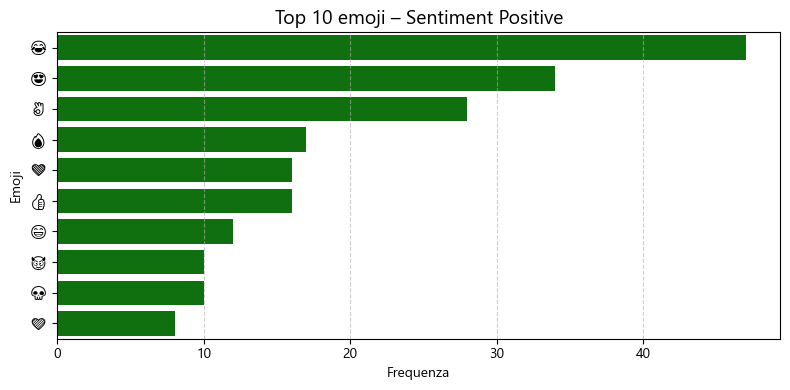

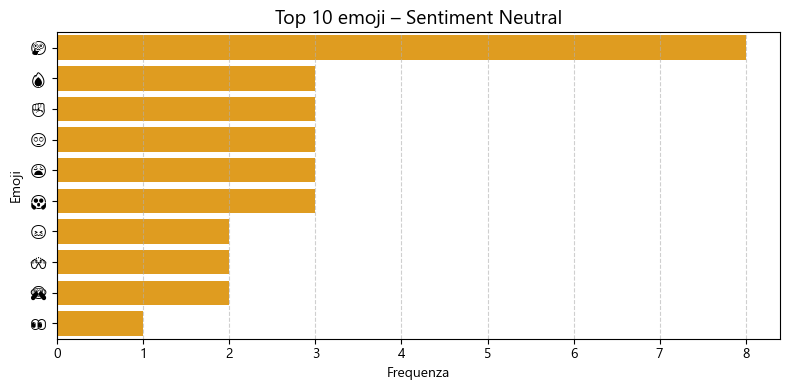

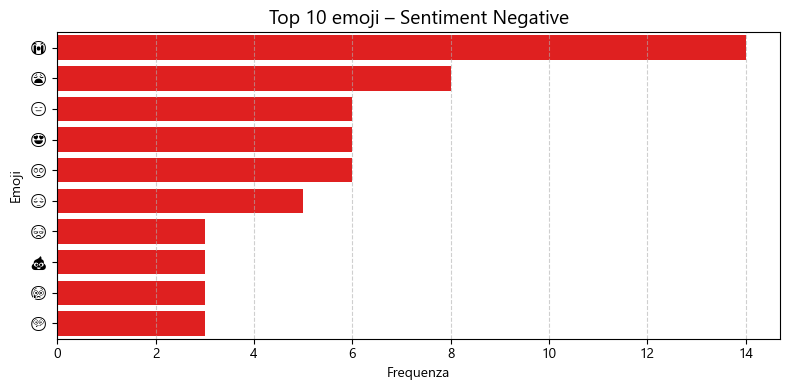

In [122]:
from matplotlib import rcParams
# Imposta il font family (Windows example)
rcParams['font.family'] = 'Segoe UI Emoji'
def plot_top_emojis(emoji_df, sentiment, color, name_image,top_n=10):
    data = emoji_df[emoji_df['sentiment_gold'] == sentiment].sort_values(by='count', ascending=False).head(top_n)
    plt.figure(figsize=(8, 4))
    sns.barplot(data=data, x='count', y='emoji_char', color=color)
    plt.title(f"Top {top_n} emoji – Sentiment {sentiment}", fontsize=14)
    plt.xlabel("Frequenza")
    plt.ylabel("Emoji")
    plt.grid(axis='x', linestyle='--', alpha=0.6)
    plt.tight_layout()
    save_path = os.path.join("assets", name_image)
    plt.savefig(save_path, bbox_inches='tight')
    plt.show()

plot_top_emojis(emoji_counts, 'Positive', 'green', "positive_emoji.png")  # Positivi
plot_top_emojis(emoji_counts, 'Neutral', 'orange', "neutral_emoji.png") # Neutri
plot_top_emojis(emoji_counts, 'Negative', 'red', "negative_emoji.png")   # Negativi


### IDEM MA CON GLI HASHTAG

In [123]:
tweet_merged = tweet.merge(df_tweet[['tweet_id', 'tweet_text']], on='tweet_id', how='left')
tweet_merged = tweet_merged.rename(columns={'original_text': 'tweet_hashtag'})
tweet_merged.drop(columns=['tweet_text_x'], inplace=True)
tweet_merged = tweet_merged.rename(columns={'tweet_text_y': 'tweet_text'})

In [124]:
tweet.to_csv('clean_tweet.csv', index=False)

In [125]:
import re

# 1. Estrai gli hashtag dal tweet text (in minuscolo per uniformità)
def extract_hashtags(text):
    return re.findall(r"#\w+", text.lower())

tweet_merged['hashtags'] = tweet_merged['tweet_text'].apply(extract_hashtags)

# 2. Espandi ogni hashtag su una nuova riga
hashtag_expanded = tweet_merged.explode('hashtags')

# 3. Rimuovi righe senza hashtag
hashtag_expanded = hashtag_expanded[hashtag_expanded['hashtags'].notna()]


In [126]:
import re

def clean_hashtag(ht):
    if re.match(r'#x[0-9a-fA-F]+', ht):
        return None  # scarta
    else:
        return ht

# Applichi la funzione alla colonna degli hashtag (dopo averli estratti)
hashtag_expanded['hashtags'] = hashtag_expanded['hashtags'].apply(clean_hashtag)


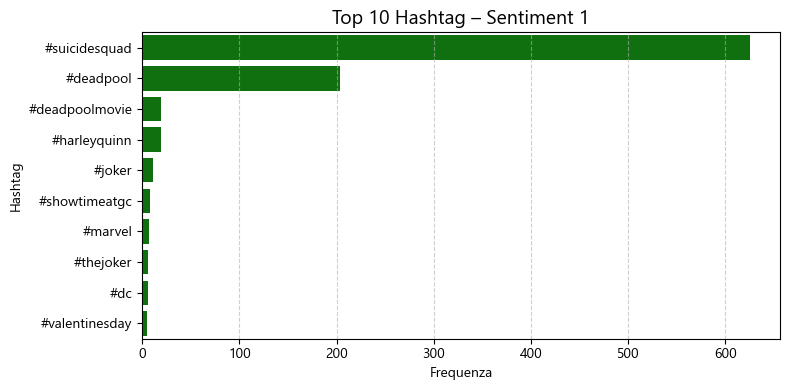

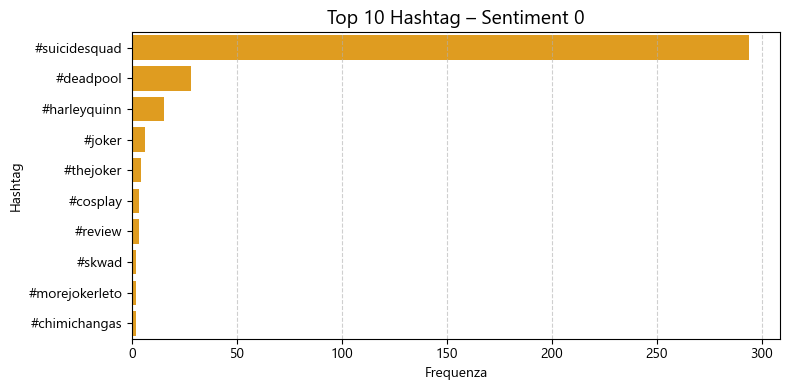

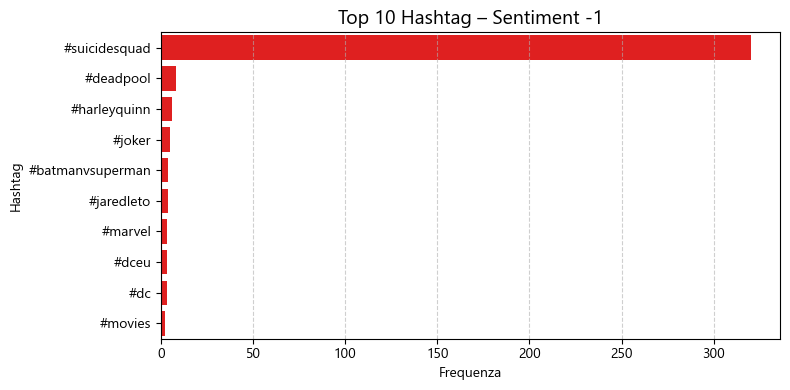

In [128]:
def plot_top_hashtags(df, sentiment_label, name_image, color='blue' , top_n=10):
    data = df[df['sentiment_gold'] == sentiment_label]
    top = data['hashtags'].value_counts().head(top_n)

    plt.figure(figsize=(8, 4))
    sns.barplot(x=top.values, y=top.index, color=color)
    plt.title(f"Top {top_n} Hashtag – Sentiment {sentiment_label}", fontsize=14)
    plt.xlabel("Frequenza")
    plt.ylabel("Hashtag")
    plt.grid(axis='x', linestyle='--', alpha=0.6)
    plt.tight_layout()
    save_path = os.path.join("assets", name_image)
    plt.savefig(save_path, bbox_inches='tight')
    plt.show()

plot_top_hashtags(hashtag_expanded, 1,"positivehashtag.png", color='green')   # Positivi
plot_top_hashtags(hashtag_expanded, 0,  "neutralhashtag.png", color='orange')  # Neutri
plot_top_hashtags(hashtag_expanded, -1, "negativehashtag.png", color='red')    # Negativi


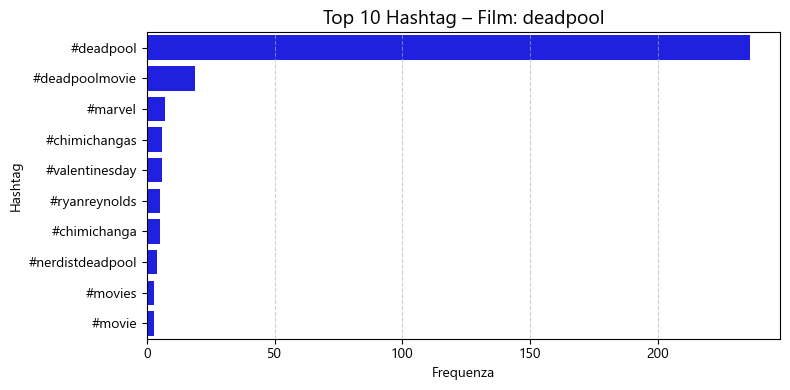

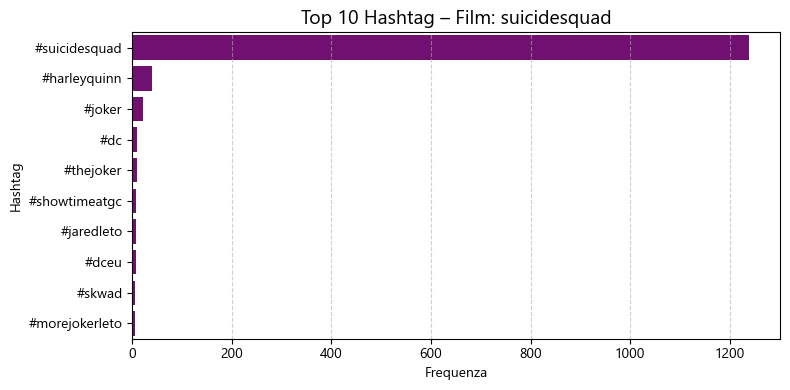

In [129]:
def plot_top_hashtags_by_movie(df, keyword, name_image, color='purple',top_n=10):
    data = df[df['keyword'] == keyword]
    top = data['hashtags'].value_counts().head(top_n)

    plt.figure(figsize=(8, 4))
    sns.barplot(x=top.values, y=top.index, color=color)
    plt.title(f"Top {top_n} Hashtag – Film: {keyword}", fontsize=14)
    plt.xlabel("Frequenza")
    plt.ylabel("Hashtag")
    plt.grid(axis='x', linestyle='--', alpha=0.6)
    plt.tight_layout()
    save_path = os.path.join("assets", name_image)
    plt.savefig(save_path, bbox_inches='tight')
    plt.show()

plot_top_hashtags_by_movie(hashtag_expanded, 'deadpool', "hashtagDP",color='blue')
plot_top_hashtags_by_movie(hashtag_expanded, 'suicidesquad',"hashtagSS", color='purple')


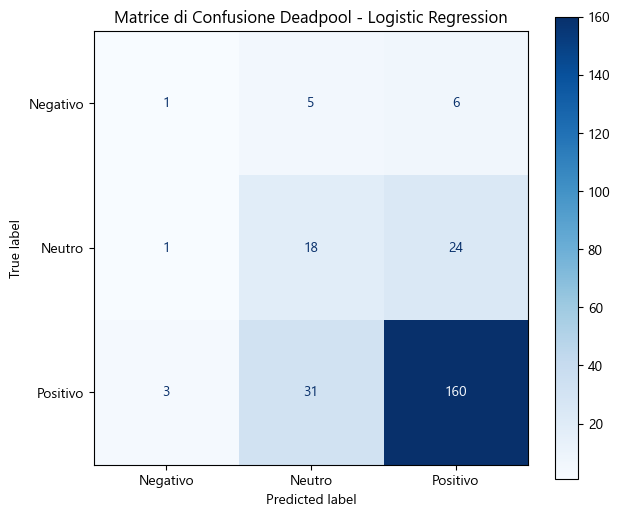

In [130]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

# y_test e y_pred sono quelli del tuo modello
labels = [-1, 0, 1]  # classi sentiment negative, neutre, positive
label_names = ['Negativo', 'Neutro', 'Positivo']

cm = confusion_matrix(y_test, y_pred, labels=labels)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)

fig, ax = plt.subplots(figsize=(7,6))
disp.plot(cmap='Blues', ax=ax, values_format='d')  # valori interi
plt.title("Matrice di Confusione Deadpool - Logistic Regression")
plt.grid(False)
plt.show()


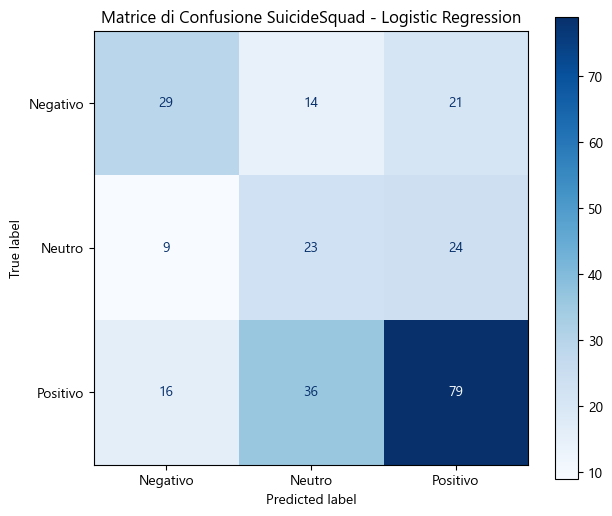

In [131]:
# y_test e y_pred sono quelli del tuo modello
labels = [-1, 0, 1]  # classi sentiment negative, neutre, positive
label_names = ['Negativo', 'Neutro', 'Positivo']

cm = confusion_matrix(y_testss, y_predss, labels=labels)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)

fig, ax = plt.subplots(figsize=(7,6))
disp.plot(cmap='Blues', ax=ax, values_format='d')  # valori interi
plt.title("Matrice di Confusione SuicideSquad - Logistic Regression")
plt.grid(False)
plt.show()

In [132]:
!pip install plotly
import plotly.graph_objects as go
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix_interactive(y_true, y_pred, labels, label_names):
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    fig = go.Figure(data=go.Heatmap(
        z=cm,
        x=label_names,
        y=label_names,
        colorscale='Blues',
        hoverongaps=False,
        text=cm,
        texttemplate="%{text}",
        reversescale=False,
        colorbar=dict(title="Count")
    ))

    fig.update_layout(
        title="Confusion Matrix Interattiva",
        xaxis_title="Predicted Label",
        yaxis_title="True Label",
        yaxis_autorange='reversed',
        width=600,
        height=600
    )

    fig.show()

# Esempio d’uso:
labels = [-1, 0, 1]
label_names = ['Negativo', 'Neutro', 'Positivo']

# y_test, y_pred: i tuoi dati veri e predetti
plot_confusion_matrix_interactive(y_test, y_pred, labels, label_names)


# BERT TUTORIAL

In [ ]:
!pip install accelerate
!pip install transformers[torch]
!pip install --upgrade datasets fsspec
!rm -rf ~/.cache/huggingface/datasets/*
!pip install transformers[torch] datasets accelerate evaluate


[notice] A new release of pip is available: 24.3.1 -> 25.1.1
[notice] To update, run: C:\Users\39345\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.3.1 -> 25.1.1
[notice] To update, run: C:\Users\39345\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


  Using cached fsspec-2025.5.1-py3-none-any.whl.metadata (11 kB)



[notice] A new release of pip is available: 24.3.1 -> 25.1.1
[notice] To update, run: C:\Users\39345\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip
"rm" non � riconosciuto come comando interno o esterno,
 un programma eseguibile o un file batch.



[notice] A new release of pip is available: 24.3.1 -> 25.1.1
[notice] To update, run: C:\Users\39345\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
        output_dir='./results',
        num_train_epochs=1,
        per_device_train_batch_size=1, #Defines the batch size for training on each device (e.g., GPU). In this case, each batch will contain 1 training example.
        fp16=False, #Disables the use of mixed-precision training with 16-bit floating-point numbers.
        warmup_steps=500, #Configures the number of steps used for a linear warmup of the learning rate.
        weight_decay=0.01, #Sets the weight decay, a regularization technique to prevent overfitting.
        logging_dir='./logs',
        prediction_loss_only=True, # Indicates that during evaluation, only the prediction loss will be computed and reported.

    )

In [ ]:
from transformers import BertTokenizer, BertModel
import torch

# Load pretrained BERT model and tokenizer
model_name = 'google-bert/bert-base-uncased'
tokenizer = BertTokenizer.from_pretrained(model_name)
model = BertModel.from_pretrained(model_name)

The total number of words in text is: 8
The total tokens in text is: 14

Each word correpsonds to at least one token:

The id n. 101	 corresponds to	 "[CLS]"
The id n. 2742	 corresponds to	 "example"
The id n. 6251	 corresponds to	 "sentence"
The id n. 2000	 corresponds to	 "to"
The id n. 14817	 corresponds to	 "extract"
The id n. 2773	 corresponds to	 "word"
The id n. 7861	 corresponds to	 "em"
The id n. 8270	 corresponds to	 "##bed"
The id n. 4667	 corresponds to	 "##ding"
The id n. 2015	 corresponds to	 "##s"
The id n. 2013	 corresponds to	 "from"
The id n. 14324	 corresponds to	 "bert"
The id n. 1012	 corresponds to	 "."
The id n. 102	 corresponds to	 "[SEP]"

Thus we get the sentence tokenized in: [101, 2742, 6251, 2000, 14817, 2773, 7861, 8270, 4667, 2015, 2013, 14324, 1012, 102]
torch.Size([14, 768])


Text(121.72222222222221, 0.5, 'Token')

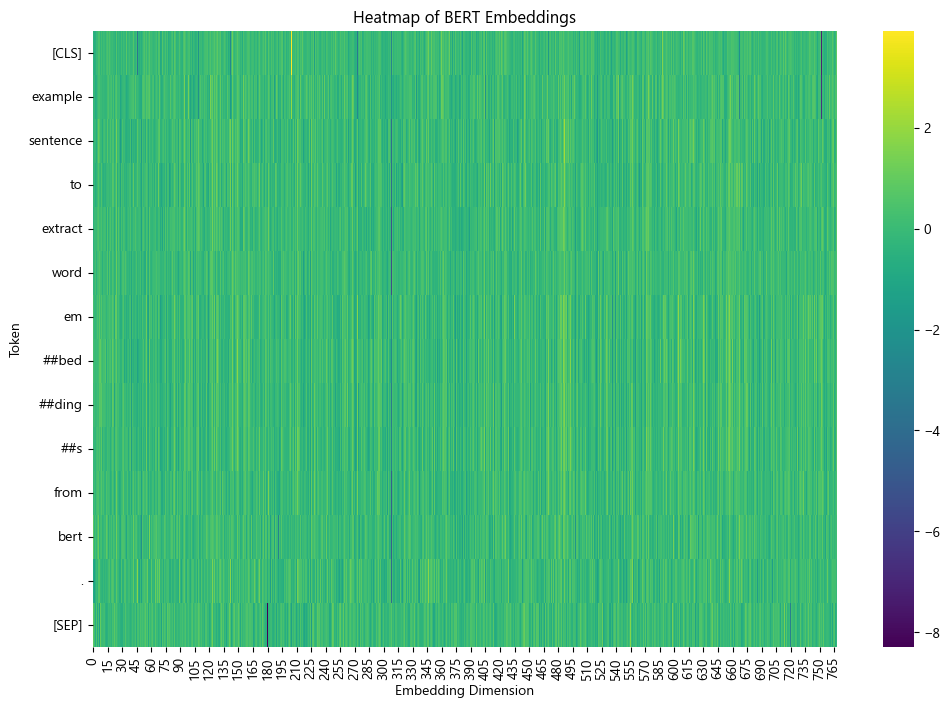

In [ ]:
# Input text
text = "Example sentence to extract word embeddings from BERT."

print(f'The total number of words in text is: {len(text.split(" "))}')

# Tokenize input text
tokens_ids = tokenizer(text).input_ids #we'll use it a lot later!
print(f'The total tokens in text is: {len(tokens_ids)}')
print('\nEach word correpsonds to at least one token:\n')

for id in tokens_ids:
    print(f'The id n. {id}\t corresponds to\t "{tokenizer.decode(id)}"')

print(f'\nThus we get the sentence tokenized in: {tokens_ids}')

# Convert tokens to a PyTorch tensor
input_ids = torch.tensor(tokens_ids).unsqueeze(0)  # Add batch dimension. Adding a dimension at the beginning (index 0) effectively turns our single sequence into a batch of size 1.

# Forward pass through BERT model
with torch.no_grad():
    outputs = model(input_ids) #this is where BERT works

embeddings = outputs.last_hidden_state.squeeze()
embeddings.shape
print(embeddings.shape)

# Convert the embeddings tensor to a numpy array for visualization
embeddings_np = embeddings.numpy()

# Generate token labels from token IDs
token_labels = [tokenizer.decode(id) for id in tokens_ids]


plt.figure(figsize=(12, 8))  # Adjust figure size as needed
sns.heatmap(embeddings_np, cmap='viridis', yticklabels=token_labels) # You can change the colormap
plt.title('Heatmap of BERT Embeddings')
plt.xlabel('Embedding Dimension')
plt.ylabel('Token')

In [ ]:
# Extract sentence embedding ([CLS] token embedding in 0th position)
sentences = [
    'The movie was a lot of fun',
    'I really enjoyed the movie',
    'I like to go to the theatre',
    'Angular is a javascript framework',
    'Python is a simple programming language',
    'C is a fast programming language',
]

input_ids = tokenizer(sentences, return_tensors='pt', padding=True)

with torch.no_grad():
    output_sent = model(**input_ids)

# get the CLS token (0th dimension)
embeddings_CLS = output_sent.last_hidden_state[:, 0, :]


embeddings_CLS

tensor([[ 0.2519, -0.0224,  0.1490,  ..., -0.2060,  0.1996,  0.0843],
        [ 0.3008, -0.2980,  0.0587,  ...,  0.0743,  0.2820, -0.0023],
        [ 0.3261,  0.1462,  0.0218,  ..., -0.3117,  0.3351,  0.3409],
        [-0.0465, -0.2262,  0.0156,  ..., -0.2055, -0.1593,  0.5124],
        [-0.1222, -0.1869, -0.0134,  ..., -0.3802, -0.2791,  0.9043],
        [-0.1136, -0.2376,  0.0053,  ..., -0.2507, -0.1619,  0.7483]])

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3)
embeddings_3d = pca.fit_transform(embeddings_CLS)
import plotly.graph_objs as go

def plot_3d(dimens, labels, title: str):
    trace = go.Scatter3d(
        x=dimens[:, 0],
        y=dimens[:, 1],
        z=dimens[:, 2],
        mode='markers',
        text=labels,
        marker=dict(
            size=10,
            color='blue',    # set color to an array/list of desired values
            opacity=0.8
        )
    )
    # Create layout
    layout = go.Layout(
        title=title,
        scene=dict(
            xaxis=dict(title='Component 1'),
            yaxis=dict(title='Component 2'),
            zaxis=dict(title='Component 3')
        )
    )
    # Create figure
    fig = go.Figure(data=[trace], layout=layout)
    # Show plot
    fig.show()

plot_3d(embeddings_3d, labels=sentences, title="Sentences embeddings with BERT")

In [ ]:
sentences = [
    'The restaurant was good',
    "The library didn't have the book I was looking for",
    "Staff is not so great but the food was good",
    "The park is to crowded in my opinion",
    "Nice location but few people were there",
    "Avoid this place"
]

input_ids = tokenizer(sentences, return_tensors='pt', padding=True)

with torch.no_grad():
    output_sent = model(**input_ids)

# get the CLS token (0th dimension)
embeddings_CLS = output_sent.last_hidden_state[:, 0, :]

pca = PCA(n_components=3)
embeddings_3d = pca.fit_transform(embeddings_CLS)
plot_3d(embeddings_3d, labels=sentences, title="Sentences embeddings with BERT, more difficult")

In [ ]:
#input = tokenizer('Very bad restaurant. Do not go there!', return_tensors='pt')
#for k in input:
 #   input[k] = input[k].to('cuda')

#output = model(**input) # input tensors are passed to the model
#predictions = output.logits #Logits are the raw, unnormalized scores output by the model before the final activation function (like softmax)

#print(predictions)
#label_predicted = predictions.argmax(-1) #This index corresponds to the class with the highest predicted probability, which is the model's predicted label for the input text
#print('The predicted score is:', label_predicted.item())

In [ ]:
def get_prediction_label(input_text, model):
    input = tokenizer(input_text, return_tensors='pt', max_length=512, truncation=True)
    #for k in input:
     #   input[k] = input[k].to('cuda')  # Sposta input su GPU (attenzione: se non hai CUDA, toglilo)
    
    output = model(**input)
    predicted = output.logits.argmax(-1)  # Trova la classe con probabilità più alta
    
    return predicted.item()  # Restituisce la classe come intero


In [ ]:
#get_prediction_label("Very good hamburger but staff was not friendly", model)

# APPLICO BERT

In [133]:
from sklearn.model_selection import train_test_split
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import TrainingArguments, Trainer

df_temp, test = train_test_split(
    tweet,
    test_size=0.2,
    stratify=tweet['sentiment_gold'],
    random_state=42
)

# 2. Dal temporaneo (80%), prendiamo 75% train (cioè 60% totale) e 25% validazione (20% totale)
train, eval = train_test_split(
    df_temp,
    test_size=0.25,  # 25% di 80% = 20%
    stratify=df_temp['sentiment_gold'],
    random_state=42
)
#train, test = train_test_split(tweet, test_size=0.2, stratify=tweet["sentiment_gold"], random_state=42)


In [134]:
test_deadpool = test[test['keyword'] == 'deadpool'].copy()
test_suicide = test[test['keyword'] == 'suicidesquad'].copy()

In [135]:
# Prendiamo i tweet negativi
negatives = train[train['sentiment_gold'] == -1]

# Calcoliamo quante volte duplicarli per bilanciare (approssimativo)
multiplier = int(train['sentiment_gold'].value_counts().max() / len(negatives))

# Li replichiamo
neg_oversampled = pd.concat([negatives] * multiplier, ignore_index=True)

# Ribilanciamo il training set
train_balanced = pd.concat([train, neg_oversampled], ignore_index=True)

# (opzionale) Shuffle
train_balanced = train_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

In [136]:
train_balanced['sentiment_gold'].value_counts(normalize=True)


sentiment_gold
-1    0.471933
 1    0.395010
 0    0.133056
Name: proportion, dtype: float64

In [137]:
from datasets import Dataset

# Prima controlla che non ci siano NaN
train_balanced = train_balanced.dropna(subset=['tweet_text', 'sentiment_gold'])
eval = eval.dropna(subset=['tweet_text', 'sentiment_gold'])
test = test.dropna(subset=['tweet_text', 'sentiment_gold'])

# Conversione in Dataset Hugging Face
dataset_train = Dataset.from_pandas(train_balanced[['tweet_text', 'sentiment_gold']], preserve_index=False)
dataset_eval = Dataset.from_pandas(eval[['tweet_text' , 'sentiment_gold']] , preserve_index= False)
dataset_test_dp = Dataset.from_pandas(test_deadpool[['tweet_text', 'sentiment_gold']], preserve_index=False)
dataset_test_ss = Dataset.from_pandas(test_suicide[['tweet_text', 'sentiment_gold']], preserve_index=False)


In [138]:
small_train_dataset = dataset_train.shuffle(seed=42).select(range(300))  
small_eval_dataset = dataset_eval.shuffle(seed=42).select(range(300))
small_test_dataset_dp = dataset_test_dp.shuffle(seed=42).select(range(250))  
small_test_dataset_ss = dataset_test_ss.shuffle(seed=42).select(range(246))  


In [139]:
#tokenizer = AutoTokenizer.from_pretrained("google-bert/bert-base-uncased")
def tokenize_function(examples):
    return tokenizer(examples["tweet_text"], padding="max_length", truncation=True)

dataset_train = dataset_train.map(tokenize_function, batched=True)
dataset_eval = dataset_eval.map(tokenize_function, batched=True)
dataset_test_dp = dataset_test_dp.map(tokenize_function, batched=True)
dataset_test_ss = dataset_test_ss.map(tokenize_function, batched=True)


small_train_dataset = small_train_dataset.map(tokenize_function, batched=True)
small_eval_dataset = small_eval_dataset.map(tokenize_function, batched=True)
small_test_dataset_dp = small_test_dataset_dp.map(tokenize_function, batched=True)
small_test_dataset_ss = small_test_dataset_ss.map(tokenize_function, batched=True)


Map:   0%|          | 0/2405 [00:00<?, ? examples/s]

NameError: name 'tokenizer' is not defined

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    "google-bert/bert-base-uncased",
    num_labels=3,
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=5e-5,
    num_train_epochs=3,
    eval_strategy="epoch",
    report_to="none",
)


In [ ]:
import evaluate

metric = evaluate.load("accuracy")
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1) 
    return metric.compute(predictions=predictions, references=labels) 

import os
os.environ["WANDB_DISABLED"] = "true"

In [ ]:
dataset_train = dataset_train.rename_column('sentiment_gold' , 'labels')
dataset_eval = dataset_eval.rename_column('sentiment_gold' , 'labels')
dataset_test_dp  = dataset_test_dp.rename_column('sentiment_gold' , 'labels')
dataset_test_ss  = dataset_test_ss.rename_column('sentiment_gold' , 'labels')


small_train_dataset= small_train_dataset.rename_column('sentiment_gold' , 'labels')
small_eval_dataset= small_eval_dataset.rename_column('sentiment_gold' , 'labels')
small_test_dataset_dp= small_test_dataset_dp.rename_column('sentiment_gold' , 'labels')
small_test_dataset_ss= small_test_dataset_ss.rename_column('sentiment_gold' , 'labels')

In [ ]:
def remap_labels(example):
    mapping = {-1: 0, 0: 1, 1: 2}
    example["labels"] = mapping[example["labels"]]
    return example

dataset_test_dp = dataset_test_dp.map(remap_labels)
dataset_test_ss = dataset_test_ss.map(remap_labels)

dataset_train = dataset_train.map(remap_labels)
dataset_eval = dataset_eval.map(remap_labels)

small_train_dataset = small_train_dataset.map(remap_labels)
small_eval_dataset = small_eval_dataset.map(remap_labels)
small_test_dataset_dp = small_test_dataset_dp.map(remap_labels)
small_test_dataset_ss = small_test_dataset_ss.map(remap_labels)



Map:   0%|          | 0/254 [00:00<?, ? examples/s]

Map:   0%|          | 0/246 [00:00<?, ? examples/s]

Map:   0%|          | 0/2405 [00:00<?, ? examples/s]

Map:   0%|          | 0/499 [00:00<?, ? examples/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

Map:   0%|          | 0/250 [00:00<?, ? examples/s]

Map:   0%|          | 0/246 [00:00<?, ? examples/s]

In [146]:

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset_train,
    eval_dataset=dataset_eval,
    compute_metrics=compute_metrics,
) 

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,No log,0.825913,0.681363
2,0.601900,0.937044,0.665331
3,0.601900,1.108024,0.675351


TrainOutput(global_step=903, training_loss=0.4555444812457823, metrics={'train_runtime': 20549.7943, 'train_samples_per_second': 0.351, 'train_steps_per_second': 0.044, 'total_flos': 1898363308907520.0, 'train_loss': 0.4555444812457823, 'epoch': 3.0})

In [149]:
trainer.evaluate(dataset_test_dp)


{'eval_loss': 0.920892059803009,
 'eval_accuracy': 0.7401574803149606,
 'eval_runtime': 203.6546,
 'eval_samples_per_second': 1.247,
 'eval_steps_per_second': 0.157,
 'epoch': 3.0}

In [ ]:
trainer.evaluate(dataset_test_ss)
#0.63

{'eval_loss': 1.3397092819213867,
 'eval_accuracy': 0.6382113821138211,
 'eval_runtime': 199.5878,
 'eval_samples_per_second': 1.233,
 'eval_steps_per_second': 0.155,
 'epoch': 3.0}

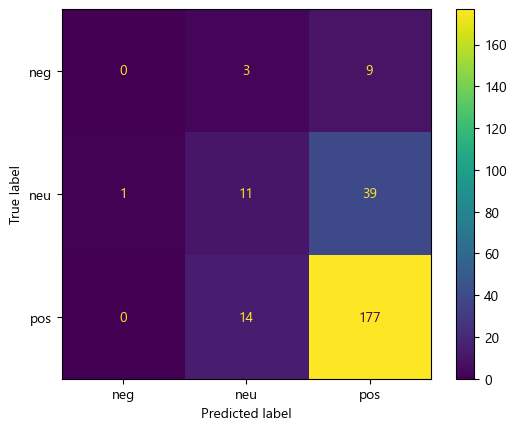

In [151]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

predictions = trainer.predict(dataset_test_dp)
y_pred_dp = np.argmax(predictions.predictions, axis=1)
y_true_dp = predictions.label_ids

cm = confusion_matrix(y_true_dp, y_pred_dp)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['neg', 'neu', 'pos'])
disp.plot()


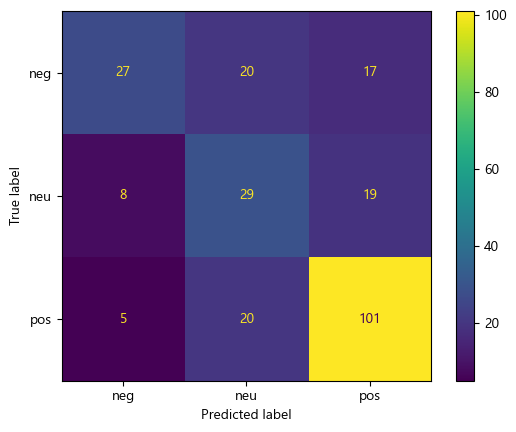

In [152]:
predictions = trainer.predict(dataset_test_ss)
y_pred_ss = np.argmax(predictions.predictions, axis=1)
y_true_ss = predictions.label_ids

cm = confusion_matrix(y_true_ss, y_pred_ss)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['neg', 'neu', 'pos'])
disp.plot()

In [153]:
inv_map = {0: -1, 1: 0, 2: 1}
y_pred_dp = [inv_map[p] for p in y_pred_dp]
y_true_dp = [inv_map[t] for t in y_true_dp]
y_pred_ss = [inv_map[p] for p in y_pred_ss]
y_true_ss = [inv_map[t] for t in y_true_ss]


In [154]:
from sklearn.metrics import accuracy_score, mean_absolute_error

acc_dp = accuracy_score(y_true_dp, y_pred_dp)
mae_dp = mean_absolute_error(y_true_dp, y_pred_dp)

acc_ss = accuracy_score(y_true_ss, y_pred_ss)
mae_ss = mean_absolute_error(y_true_ss, y_pred_ss)

print(f"BERT Deadpool – Accuracy: {acc_dp:.3f}, MAE: {mae_dp:.3f}")
print(f"BERT Suicide Squad – Accuracy: {acc_ss:.3f}, MAE: {mae_ss:.3f}")


BERT Deadpool – Accuracy: 0.740, MAE: 0.295
BERT Suicide Squad – Accuracy: 0.638, MAE: 0.451


In [ ]:
acc_dp #bert
accuracy_dp #afinn
accuracy_dp_logregr #log regression

acc_ss
accuracy_ss
accuracy_ss_logregr

0.78

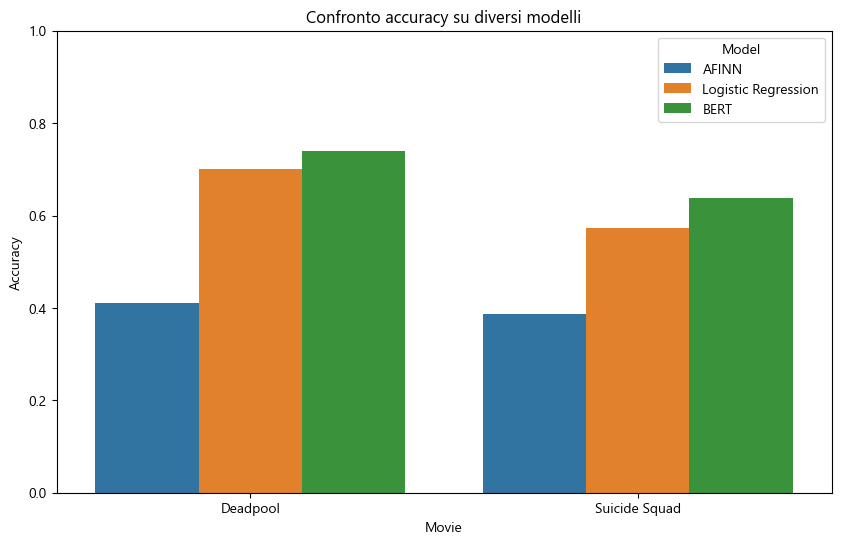

In [157]:
accuracies = {
    'Deadpool': {
        'AFINN': accuracy_dp,
        'Logistic Regression': accuracy_dp_logregr,
        'BERT': acc_dp,
    },
    'Suicide Squad': {
        'AFINN': accuracy_ss,
        'Logistic Regression': accuracy_ss_logregr,
        'BERT': acc_ss,
    }
}

df_acc = pd.DataFrame([
    {'Movie': movie, 'Model': model, 'Accuracy': acc}
    for movie, models in accuracies.items()
    for model, acc in models.items()
])

plt.figure(figsize=(10,6))
sns.barplot(data=df_acc, x='Movie', y='Accuracy', hue='Model')
plt.title('Confronto accuracy su diversi modelli')
plt.ylim(0, 1)
plt.show()



## VISUALIZZAZIONE EMBEDDINGS

In [158]:
sample_df = test.sample(n=31, random_state=42).reset_index(drop=True)


In [159]:
import torch
from tqdm import tqdm
import numpy as np

# Tokenizzazione
encoded = tokenizer(list(sample_df['tweet_text']), padding=True, truncation=True, return_tensors='pt')

# Estrai gli embedding [CLS]
model.eval()
with torch.no_grad():
    outputs = model(**encoded)
    cls_embeddings = outputs.logits


In [160]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=3, perplexity=30, random_state=42)
embeddings_3d = tsne.fit_transform(cls_embeddings)


In [161]:
import plotly.express as px

# Colori per etichette: 0=neg, 1=neutro, 2=pos
color_map = {0: "red", 1: "gray", 2: "green"}
sent_labels = test['sentiment_gold'].map(color_map)

fig = px.scatter_3d(
    x=embeddings_3d[:, 0],
    y=embeddings_3d[:, 1],
    z=embeddings_3d[:, 2],
    color=sample_df['sentiment_gold'].astype(str),
    hover_name=sample_df['tweet_text'],  # Mostra il testo come tooltip
    title="BERT embeddings (CLS) - Sampled Tweets",
    labels={'color': 'Sentiment'},
    opacity=0.7
)

fig.show()


### CONFRONTO SENTIMENT VS BERT

In [162]:
# Tokenizzazione del test set
encoded_test = tokenizer(
    list(dataset_test_dp['tweet_text']),
    padding=True,
    truncation=True,
    return_tensors='pt'
)

# Sposta su GPU se disponibile
encoded_test = {k: v.to(model.device) for k, v in encoded_test.items()}

# Predizione
model.eval()
with torch.no_grad():
    logits = model(**encoded_test).logits
    y_pred_dp = logits.argmax(dim=1).cpu().numpy()


In [164]:
df_test_dp

,tweet_text,labels,input_ids,token_type_ids,attention_mask
0,deadpool friday who be come,1,"[101, 2757, 16869, 5958, 2040, 2022, 2272, 102...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, ..."
1,need someone watch deadpool,2,"[101, 2342, 2619, 3422, 2757, 16869, 102, 0, 0...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,deadpool good one thank,2,"[101, 2757, 16869, 2204, 2028, 4067, 102, 0, 0...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, ..."
3,tell myprofessor study exam really need go see...,2,"[101, 2425, 2026, 21572, 7959, 24137, 2099, 28...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ..."
4,dunk contest deadpool right hopefully finally ...,2,"[101, 24654, 2243, 5049, 2757, 16869, 2157, 11...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, ..."
...,...,...,...,...,...
249,witness great movie ever make ever make deadpool,2,"[101, 7409, 2307, 3185, 2412, 2191, 2412, 2191...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, ..."
250,love blind blind deadpool ryanreynold 👻 💩 l,2,"[101, 2293, 6397, 6397, 2757, 16869, 4575, 152...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, ..."
251,might go see deadpool saturday work 😁 😁 😁,2,"[101, 2453, 2175, 2156, 2757, 16869, 5095, 214...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, ..."
252,like win ticket see deadpool romantic dinner <...,2,"[101, 2066, 2663, 7281, 2156, 2757, 16869, 629...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, ..."


In [166]:
df_test_dp = dataset_test_dp.to_pandas()

# Creiamo il DataFrame con gold e predizioni
sample_dp = df_test_dp[['tweet_text', 'labels']].copy()
sample_dp['predicted'] = y_pred_dp

# Rinominiamo per leggibilità (opzionale)
label_map = {0: "Negative", 1: "Neutral", 2: "Positive"}
sample_dp['labels'] = sample_dp['labels'].map(label_map)
sample_dp['predicted'] = sample_dp['predicted'].map(label_map)

# Estrai 20 esempi a caso
sample_20 = sample_dp.sample(20, random_state=42).reset_index(drop=True)

# Mostra
pd.set_option('display.max_colwidth', 100)
display(sample_20)


,tweet_text,labels,predicted
0,deadpool hand good movie I ve ever see,Positive,Positive
1,oh magnificent fuck arsehole wonderful deadpool,Positive,Positive
2,deadpool seriously good comic adaption ever see unicorn,Positive,Positive
3,like video video look like rape deadpool scarce,Positive,Positive
4,bruh saw lot people make movie tonight like u go to spend 20 ticket kiss bruh deadpool chill,Positive,Positive
5,deadpool ' s end fuck gold,Positive,Positive
6,deadpool must friday,Positive,Positive
7,purpose life deadpool thankyou,Positive,Positive
8,see deadpool really rape joke 😔,Neutral,Positive
9,time deadpool,Positive,Positive


In [167]:
# Tokenizzazione del test set
encoded_test = tokenizer(
    list(dataset_test_ss['tweet_text']),
    padding=True,
    truncation=True,
    return_tensors='pt'
)

# Sposta su GPU se disponibile
encoded_test = {k: v.to(model.device) for k, v in encoded_test.items()}

# Predizione
model.eval()
with torch.no_grad():
    logits = model(**encoded_test).logits
    y_pred_ss = logits.argmax(dim=1).cpu().numpy()

In [169]:
df_test_ss = dataset_test_ss.to_pandas()

# Creiamo il DataFrame con gold e predizioni
sample_ss = df_test_ss[['tweet_text', 'labels']].copy()
sample_ss['predicted'] = y_pred_ss

# Rinominiamo per leggibilità (opzionale)
label_map = {0: "Negative", 1: "Neutral", 2: "Positive"}
sample_ss['labels'] = sample_ss['labels'].map(label_map)
sample_ss['predicted'] = sample_ss['predicted'].map(label_map)

# Estrai 20 esempi a caso
sample_20 = sample_ss.sample(20, random_state=42).reset_index(drop=True)

# Mostra
pd.set_option('display.max_colwidth', 100)
display(sample_20)

,tweet_text,labels,predicted
0,saw suicide squad amazing go see week one friend suicidesquad,Positive,Positive
1,highly recommend suicidesquad anyone think see,Positive,Positive
2,invite suicidesquad premiere today dress code edgy not kid say edgy,Neutral,Neutral
3,topic real listen suicidesquad,Neutral,Neutral
4,make joker incredibly sexy purpose 🤔 suicidesquad,Positive,Positive
5,suicidesquad first movie year want walk right back another show fun,Positive,Positive
6,wish suicidesquad would end harley quinn put bullet joker ' s head tbh,Negative,Negative
7,suicidesquad well expect that be mainly 0 expectation saw review,Positive,Neutral
8,suicidesquad kind disappointment soundtrack phenomenal,Neutral,Positive
9,type suicidesquad voicemail thought realize say think,Neutral,Negative


#### PRELIMINARY RESULTS

In [176]:
print("Etichette vere:", sorted(set(df_test_dp['labels'])))
print("Etichette predette:", sorted(set(y_pred_dp)))


Etichette vere: [0, 1, 2]
Etichette predette: [-1, 0, 1]


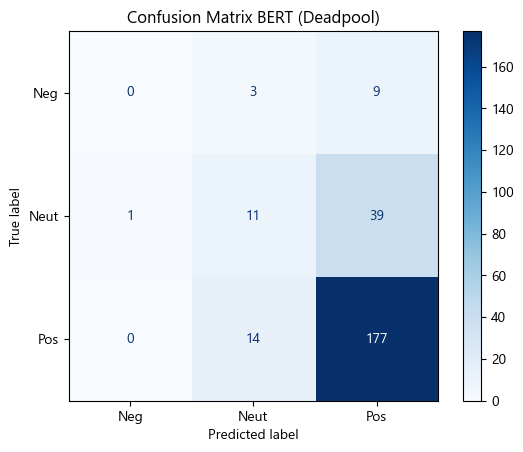

In [177]:
mapping = {-1: 0, 0: 1, 1: 2}
y_pred_dp = [mapping[p] for p in y_pred_dp]

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(df_test_dp['labels'], y_pred_dp)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Neg', 'Neut', 'Pos'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix BERT (Deadpool)")
plt.show()


In [180]:
errors = sample_dp[sample_dp['predicted'] != sample_dp['labels']]
errors.sample(10, random_state=42)[['tweet_text', 'labels', 'predicted']]


,tweet_text,labels,predicted
178,deadpool tonight who be go nerdgasm spiderman sequelidea retroreplay,Positive,Neutral
237,do deadpool ⚔ johor bahru city square,Neutral,Positive
3,tell myprofessor study exam really need go see deadpool think understand 😅,Positive,Neutral
150,colossus tell deadpool hero end,Neutral,Positive
20,deadpool minute feel like lose brain cell watch gop debate,Positive,Neutral
239,deadpool ' s script predictable still funny dat great,Neutral,Positive
55,ha ha accord movie deadpool confession see leak work print,Neutral,Positive
37,bf want see deadpool wanna see hail caesar,Neutral,Positive
253,wanna watch weird grainy version deadpool need see baby screen dammit,Neutral,Positive
95,end credit deadpool,Neutral,Positive


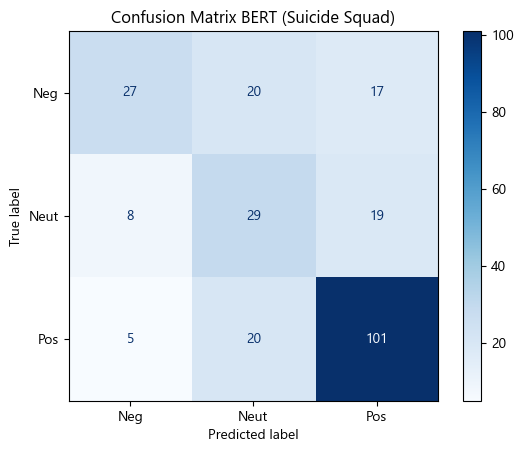

In [184]:
mapping = {-1: 0, 0: 1, 1: 2}
y_pred_ss= [mapping[p] for p in y_pred_ss]

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(df_test_ss['labels'], y_pred_ss)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Neg', 'Neut', 'Pos'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix BERT (Suicide Squad)")
plt.show()

 #### PREDIZIONE TWEET NUOVI

In [189]:
def get_prediction_label(text):
    input = tokenizer(text, return_tensors='pt', truncation=True, padding=True)
    output = model(**input)
    return output.logits.argmax(-1).item()

# Esempio
print(get_prediction_label("fI dont like ite"))


1


# SHAP

In [164]:
pip install shap accelerate transformers torch


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 25.1.1
[notice] To update, run: C:\Users\39345\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [190]:
import shap

def predict_prob(texts):
    # Forza la conversione in lista di stringhe
    if isinstance(texts, np.ndarray):
        texts = texts.tolist()
    texts = [str(t) for t in texts]

    # Tokenizza
    inputs = tokenizer(texts, return_tensors="pt", padding=True, truncation=True, max_length=512)
    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    # Predizione con il modello
    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.nn.functional.softmax(outputs.logits, dim=-1)

    return probs.cpu().numpy()



In [191]:
sample_texts = test['tweet_text'][:20]  # oppure usa un DataFrame se preferisci
sample_texts = sample_texts.tolist()


In [192]:
explainer = shap.Explainer(predict_prob, tokenizer)
shap_values = explainer(sample_texts)
shap_values.output_names = ['neg', 'neut', 'pos']


  0%|          | 0/210 [00:00<?, ?it/s]

PartitionExplainer explainer:  30%|███       | 6/20 [00:35<00:25,  1.84s/it]

  0%|          | 0/210 [00:00<?, ?it/s]

PartitionExplainer explainer:  40%|████      | 8/20 [00:42<00:29,  2.46s/it]

  0%|          | 0/342 [00:00<?, ?it/s]

PartitionExplainer explainer:  50%|█████     | 10/20 [00:59<00:51,  5.20s/it]

... (4 outputs left out)

  0%|          | 0/210 [00:00<?, ?it/s]

PartitionExplainer explainer:  95%|█████████▌| 19/20 [01:41<00:03,  3.02s/it]

  0%|          | 0/306 [00:00<?, ?it/s]

PartitionExplainer explainer: 21it [01:52,  5.62s/it]                        


In [193]:
shap.plots.text(shap_values[0])  # Cambia indice per altri tweet


In [194]:
shap.plots.text(shap_values)

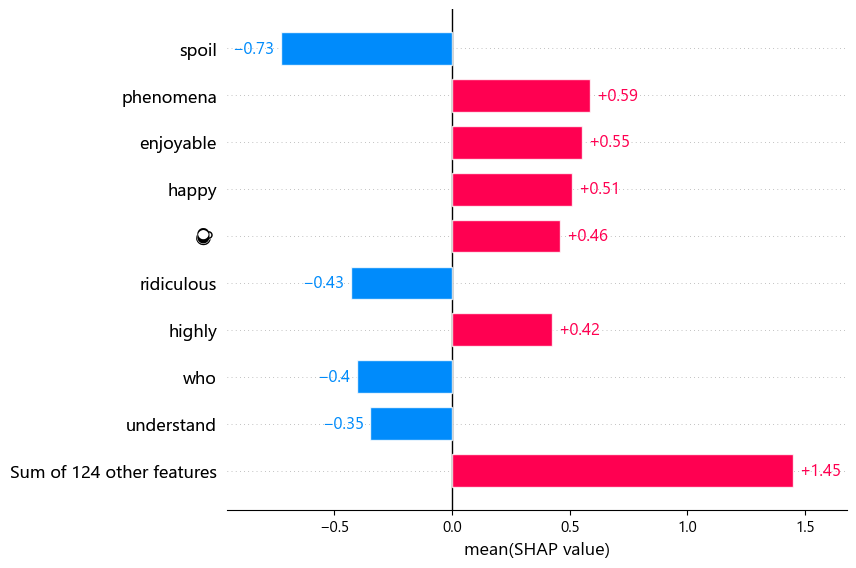

In [195]:
shap.plots.bar(shap_values[:, :, 2].mean(0))


In [196]:
df_test_dp = dataset_test_dp.to_pandas()
df_test_dp['predicted'] = y_pred_dp  # Assicurati che y_pred abbia stesso ordine

df_test_ss = dataset_test_ss.to_pandas()
df_test_ss['predicted'] = y_pred_ss

In [198]:
df_errors_dp = df_test_dp[df_test_dp['predicted'] != df_test_dp['labels']]
df_errors_ss = df_test_ss[df_test_ss['predicted'] != df_test_ss['labels']]


In [199]:
texts_to_explain_dp = df_errors_dp['tweet_text'].sample(5, random_state=42).tolist()
texts_to_explain_ss = df_errors_ss['tweet_text'].sample(5, random_state=42).tolist()


In [200]:
shap_values_dp = explainer(texts_to_explain_dp)
shap_values_ss = explainer(texts_to_explain_ss)

  0%|          | 0/380 [00:00<?, ?it/s]

PartitionExplainer explainer:  60%|██████    | 3/5 [00:19<00:03,  1.74s/it]

  0%|          | 0/342 [00:00<?, ?it/s]

PartitionExplainer explainer: 6it [00:42,  8.41s/it]                       


  0%|          | 0/210 [00:00<?, ?it/s]

  0%|          | 0/380 [00:00<?, ?it/s]

PartitionExplainer explainer:  80%|████████  | 4/5 [00:00<?, ?it/s]

  0%|          | 0/210 [00:00<?, ?it/s]

PartitionExplainer explainer: 6it [00:30, 15.33s/it]               


In [ ]:
#shap_values.output_names = ['neg', 'neut', 'pos']
for i in range(len(texts_to_explain_dp)):
    print(f"\nTweet: {texts_to_explain_dp[i]}")
    print(f"Gold label: {df_errors_dp.iloc[i]['labels']}")
    print(f"Predicted: {df_errors_dp.iloc[i]['predicted']}")
    shap.plots.text(shap_values_dp[i])



Tweet: deadpool tonight who be go nerdgasm spiderman sequelidea retroreplay
Gold label: 2
Predicted: 1



Tweet: do deadpool ⚔ johor bahru city square
Gold label: 1
Predicted: 2



Tweet: tell myprofessor study exam really need go see deadpool think understand 😅
Gold label: 1
Predicted: 2



Tweet: colossus tell deadpool hero end
Gold label: 2
Predicted: 1



Tweet: deadpool minute feel like lose brain cell watch gop debate
Gold label: 0
Predicted: 2


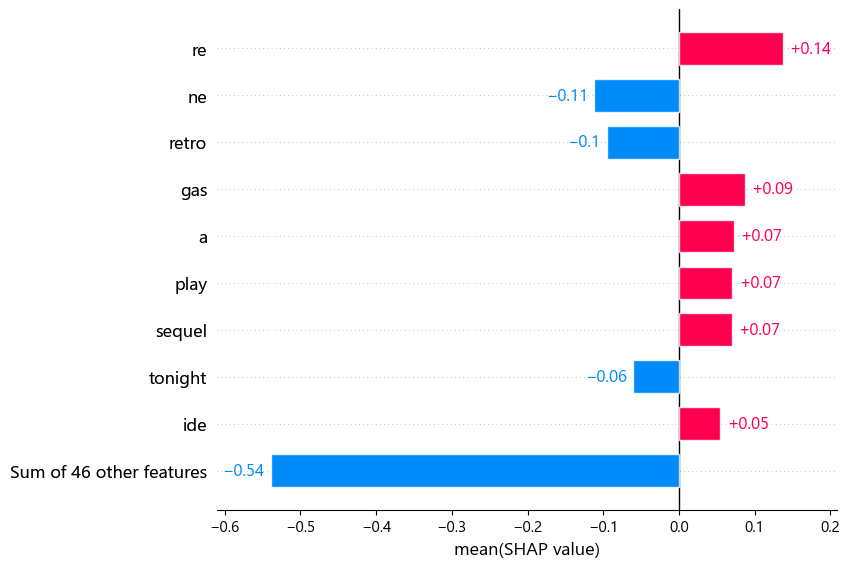

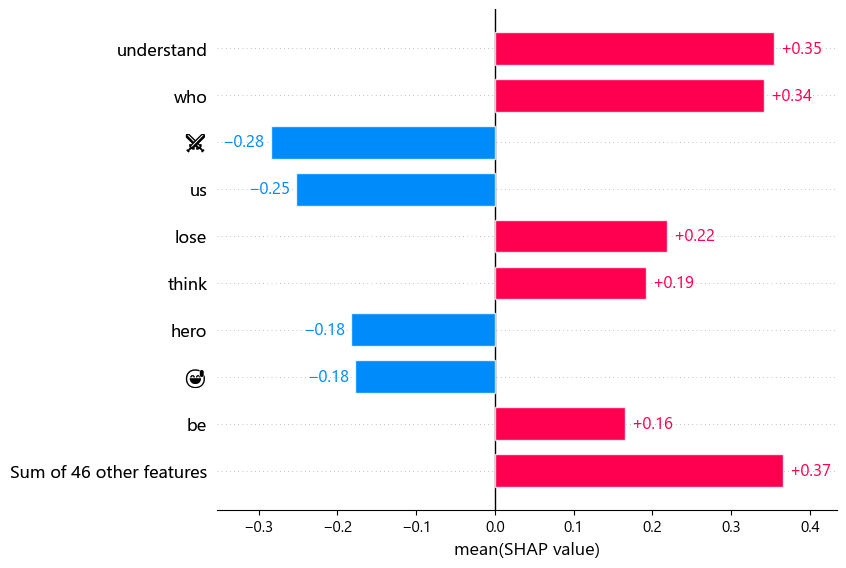

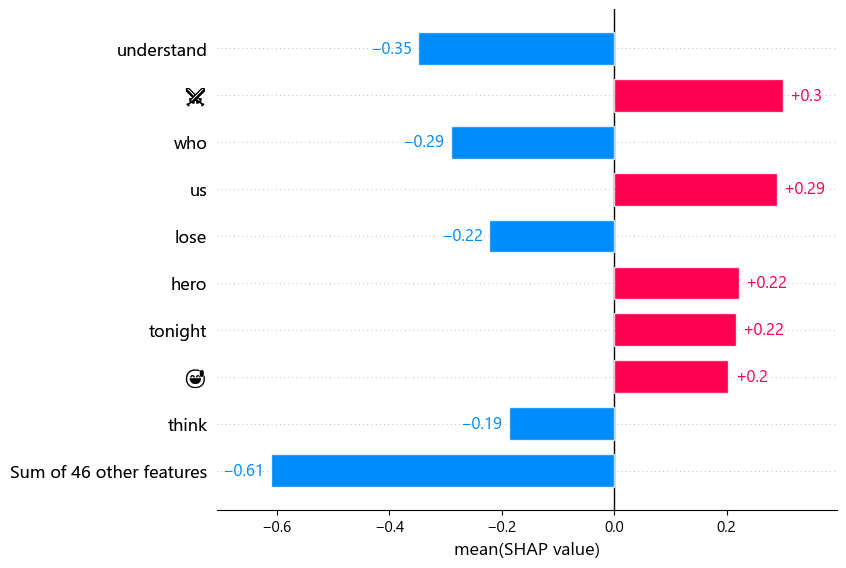

In [210]:
label_names = ['neg', 'neut', 'pos']

for idx, label in enumerate(label_names):
    shap.plots.bar(shap_values_dp[:, :, idx].mean(0), show=True)


In [211]:
for i in range(len(texts_to_explain_ss)):
    print(f"\nTweet: {texts_to_explain_ss[i]}")
    print(f"Gold label: {df_errors_ss.iloc[i]['labels']}")
    print(f"Predicted: {df_errors_ss.iloc[i]['predicted']}")
    shap.plots.text(shap_values_ss[i])



Tweet: break box office record despite lousy review
Gold label: 1
Predicted: 2



Tweet: might hit movie suicidesquad
Gold label: 2
Predicted: 0



Tweet: put movie put much possible like cheese always add suicidesquad
Gold label: 0
Predicted: 2



Tweet: jar leto \ x92 joker star suicide squad music video actual movie suicidesquad
Gold label: 1
Predicted: 2



Tweet: joker groan every time appear 15 minute screentime suicidesquad
Gold label: 0
Predicted: 2


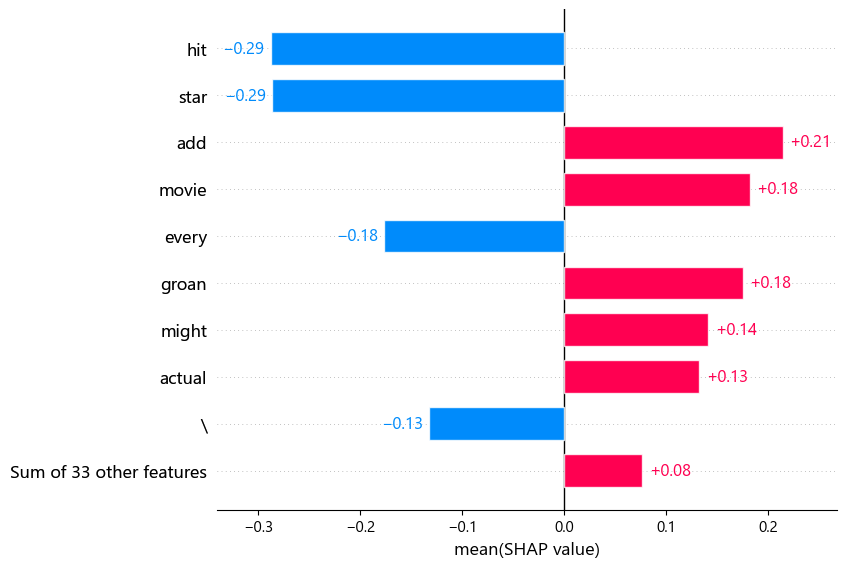

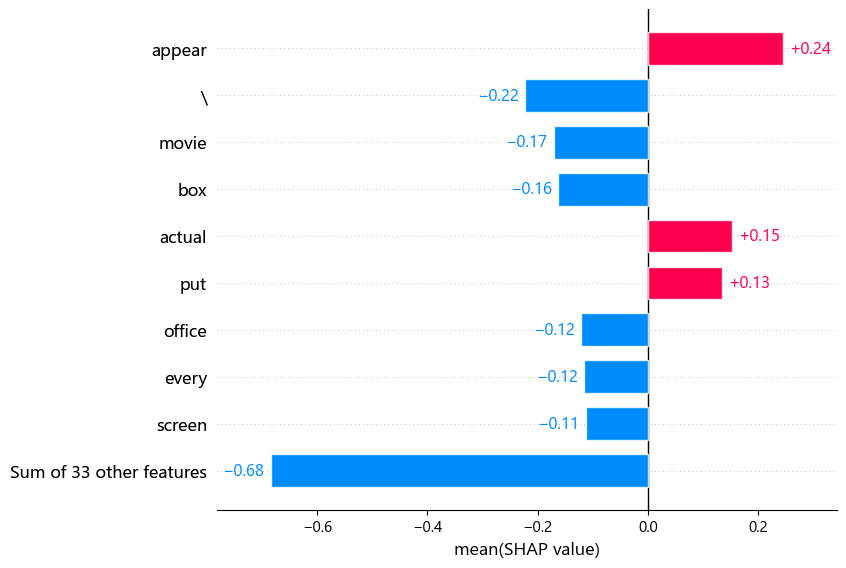

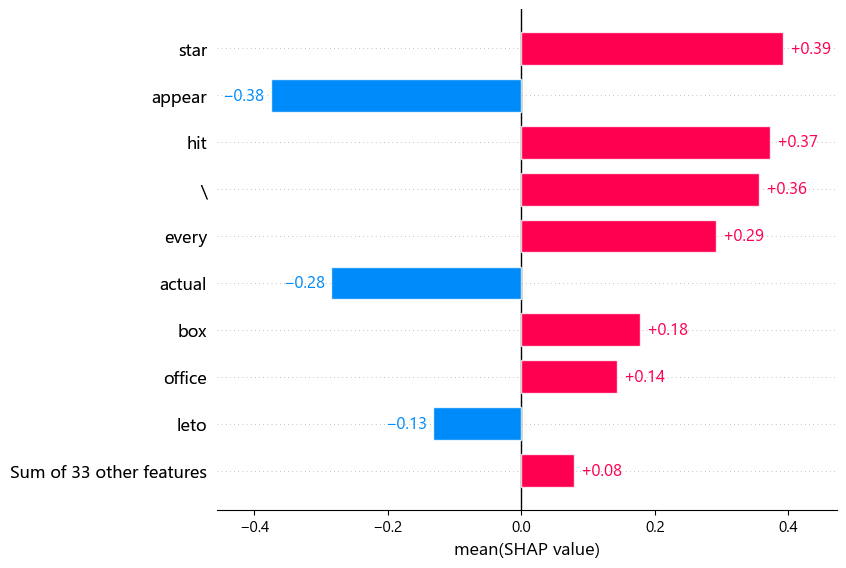

In [212]:
label_names = ['neg', 'neut', 'pos']

for idx, label in enumerate(label_names):
    shap.plots.bar(shap_values_ss[:, :, idx].mean(0), show=True)
